# MASSIVE en-US: Joint Intent Classification and Slot Filling

**SC4002 Group Assignment, `main.ipynb`** · Group ID: _fill in_ · Members: _fill in_

One shared model predicts the intent (60 classes) and the BIO slot labels (55 slot types, 108 observed
BIO labels) of each utterance. Fixed word embedding for both stages: **NLPL Wikipedia Word2Vec 2017,
model 6** (300-d, 302,866 vectors). No pretrained language model is used; every system stays under
**20,000,000 parameters**, embedding table included. Train is used for training only, dev for all
selection, and test is evaluated once, after all selection, from saved checkpoints (see Final evaluation).

Stage 1 is the baseline. Stage 2 systems trained below, selected on dev from the full method ladder:

| System | Size | Status |
|---|---|---|
| `strict_single` | 1 model(s) | plain reading of the rules |
| `flagged_single` | 1 model(s) | needs lecturer OK |

> **Integrity note.** The assignment requires the Stage-1 baseline to be developed without generative-AI
> assistance. All code below, Stage 1 included, was produced with AI assistance (Claude). Replace the
> Stage-1 sections with the group's independently written baseline before submitting, and record the AI
> use in `ai_collaboration.md`.

> **Data note.** This notebook reads the verified CSV `data/massive_enUS_full.csv`. The assignment expects
> the official `1.0/data/en-US.jsonl`; swap the loader in section 2 before submitting.

## 0. Environment
Requires `torch`, `numpy`, `pandas`, `scikit-learn`, `sentencepiece`, `psutil`, `matplotlib`. The dataset is read from `data/`, and the Word2Vec archive is downloaded to `data/nlpl_model_6/` if missing. Neither is part of the submission.

In [1]:
import platform, torch, numpy, pandas, sklearn, sentencepiece, types
print("python", platform.python_version(), "| torch", torch.__version__, "| CUDA", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

python 3.10.4 | torch 1.13.1+cu117 | CUDA True NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Configuration, reproducibility and machine safety

In [2]:
"""Paths, constants and reproducibility helpers shared by every experiment."""
import os

os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

import random
from dataclasses import dataclass, asdict, fields
from pathlib import Path

import numpy as np
import torch

torch.set_num_threads(4)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
CSV_PATH = DATA_DIR / "massive_enUS_full.csv"
W2V_DIR = DATA_DIR / "nlpl_model_6"
CACHE_DIR = ROOT / "cache"
CKPT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"
for _d in (CACHE_DIR, CKPT_DIR, RESULTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

EXPECTED_SPLITS = {"train": 11514, "dev": 2033, "test": 2974}
PARAM_CAP = 20_000_000
SEED = 42
MAX_LEN = 64
MAX_CHARS = 24
W2V_DIM = 300

_force_cpu = bool(os.environ.get("MASSIVE_CPU"))
DEVICE = torch.device("cuda" if torch.cuda.is_available() and not _force_cpu else "cpu")


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def _known_fields(cls, d):
    names = {f.name for f in fields(cls)}
    return {k: v for k, v in d.items() if k in names}


@dataclass
class ModelConfig:
    """Architecture switches. Defaults reproduce the hand-off Stage-1 model exactly."""
    # encoder
    encoder: str = "transformer"        # "transformer" | "bilstm"
    d_model: int = 256
    n_heads: int = 4
    n_layers: int = 4
    d_ff: int = 768
    dropout: float = 0.15
    lstm_hidden: int = 128              # per direction, bilstm only
    lstm_layers: int = 2
    pre_lstm: bool = False              # zero-init residual BiLSTM before the Transformer
    rel_bias: bool = False              # learned relative-position attention bias (TENER-style)
    task_top: bool = False              # one private top Transformer layer per task
    coint: bool = False                 # co-interactive attention between intent and slot streams
    # word representation
    adapters: tuple = ()                # subset of ("bpe", "ngram", "char")
    n_frozen: int = 0                   # frozen Word2Vec rows (extended vocabulary)
    frozen_dim: int = 300               # < 300: rows stored PCA-compressed
    frozen_map: bool = True             # trainable map from frozen rows into embedding space
    gaz: bool = False                   # train-only mention table as input, leave-one-out on train
    anchor: bool = False                # keep a frozen Word2Vec copy for the L2-SP penalty
    dual_emb: bool = False              # intent reads a second pass over the frozen Word2Vec copy
    # intent head
    pooling: str = "mean"               # "mean" | "meanmax" | "attn"
    label_attn: bool = False            # per-intent attention over tokens
    hier_intent: bool = False           # add a scenario score (intent = scenario_action) + aux loss
    slot_to_intent: bool = False        # intent head also sees the mean slot-label distribution
    wide_intent: int = 0                # sparse linear intent path: k word + k char TF-IDF features
    wide_mix: float = 0.5               # weight of the deep path when the two are mixed at evaluation
    supcon_dim: int = 0                 # projection size of a supervised contrastive term
    # slot head
    slot_head: str = "linear"           # "linear" | "crf" | "biaffine"
    tag_scheme: str = "bio"             # "bio" | "bioes"
    decode: str = "greedy"              # linear head only: "greedy" | "viterbi" with hard tag rules
    factorized: bool = False            # tag score = full + boundary + type
    interaction: bool = False           # slot head also sees the pooled utterance vector
    intent_to_slot: bool = False        # slot scores get a bias from the intent distribution
    refine: bool = False                # SlotRefine-style second pass fed with first-pass B- tags
    presence: bool = False              # head predicting which slot types occur in the utterance
    wide_slot_bits: int = 0             # sparse linear tag path over hashed lexical features, 2**bits
    wide_slot_mix: float = 0.5          # weight of the sparse tag path at evaluation
    # auxiliary training-only heads
    aux_lm: bool = False                # predict the original word at simulated-OOV positions

    def to_dict(self):
        d = asdict(self)
        d["adapters"] = list(self.adapters)
        return d

    @classmethod
    def from_dict(cls, d):
        d = _known_fields(cls, d)
        d["adapters"] = tuple(d.get("adapters", ()))
        return cls(**d)


@dataclass
class TrainConfig:
    """Optimisation switches. Defaults reproduce the hand-off Stage-1 recipe exactly."""
    epochs: int = 12
    patience: int = 3
    lr: float = 3e-4
    weight_decay: float = 1e-4
    batch_size: int = 64
    clip: float = 1.0
    schedule: str = "constant"          # "constant" | "cosine"
    warmup_epochs: float = 0.0
    label_smoothing: float = 0.0
    # simulated OOV (training only). Per-token rate = word + slot*in_gold_slot + a/(a+train_count)
    word_dropout: float = 0.0
    slot_dropout: float = 0.0
    rare_alpha: float = 0.0
    mention_dropout: float = 0.0        # P(a whole gold span becomes <UNK>)
    swap_frac: float = 0.0              # share of simulated tokens sent to their frozen row, not <UNK>
    swap_prob: float = 0.0              # extra uniform rate of train word -> its frozen row
    # utterance recombination from train tokens; flagged because it creates new token sequences
    mention_replace: float = 0.0        # swap slot values within a type
    lwtr: float = 0.0                   # label-wise token replacement
    sis: float = 0.0                    # shuffle tokens within each slot span
    # loss weights
    lambda_intent: float = 1.0
    lambda_slot: float = 1.0
    lambda_token_intent: float = 0.0    # stack-propagation style per-token intent loss
    lambda_aux: float = 0.0             # weight of the aux_lm head
    lambda_presence: float = 0.2        # weight of the slot-type presence head
    o_weight: float = 1.0               # CE weight of the O tag (linear head only)
    boundary_eps: float = 0.0           # biaffine head: boundary smoothing (Zhu & Li 2022)
    # sparse linear paths
    wide_lr: float = 0.05
    wide_wd: float = 0.01
    wide_dropout: float = 0.3
    # regularisers
    adv_eps: float = 0.0                # adversarial embedding noise, relative to embedding norm
    rdrop_alpha: float = 0.0            # consistency between two dropout passes
    cons_alpha: float = 0.0             # consistency between word-dropped and clean views
    sam_rho: float = 0.0                # sharpness-aware minimisation radius
    mixup_alpha: float = 0.0            # sentence mixup on the intent head
    supcon_lambda: float = 0.0          # supervised contrastive term (needs supcon_dim)
    anchor_lambda: float = 0.0          # L2-SP pull of used word rows towards Word2Vec (needs anchor)
    # other
    emb_lr_mult: float = 1.0            # LR multiplier for the trainable word table (0 = frozen)
    ema_decay: float = 0.0              # 0 disables EMA weight averaging
    seed: int = SEED

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, d):
        return cls(**_known_fields(cls, d))

In [3]:
"""Protects the laptop during long unattended training: pause on heat or low memory.

The machine rebooted uncleanly during an earlier run (GPU shared with another process, little
free RAM), so every run checks free RAM, GPU temperature and free VRAM, and waits instead of
pushing on. If the condition does not clear, it stops cleanly: the best checkpoint is already on
disk and the ladder resumes where it stopped.
"""
import subprocess
import time

import psutil

MIN_RAM_MB = 900            # pause below this much available system RAM
MAX_TEMP_C = 86             # pause at or above this GPU temperature ...
RESUME_TEMP_C = 76          # ... and resume at or below this one
START_TEMP_C = 80           # a new run waits until the GPU has cooled to this
MIN_FREE_VRAM_MB = 1500     # needed before a run allocates its model
MAX_WAIT_S = 3600           # give up (cleanly) after this long
THROTTLE_S = 20             # do not query the hardware more often than this during training

_last_check = 0.0


class ResourceAbort(RuntimeError):
    """Raised when the machine stayed unsafe for MAX_WAIT_S."""


def _gpu():
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=temperature.gpu,memory.used,memory.total",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=20).stdout
        temp, used, total = [int(x) for x in out.strip().splitlines()[0].split(",")]
        return temp, total - used
    except Exception:  # no GPU tool available: only the RAM check applies
        return None, None


def _reasons(need_vram, cooling):
    reasons = []
    avail = psutil.virtual_memory().available / 1e6
    if avail < MIN_RAM_MB:
        reasons.append(f"low RAM {avail:.0f} MB")
    temp, free_vram = _gpu()
    if temp is not None:
        limit = RESUME_TEMP_C if cooling else (START_TEMP_C if need_vram else MAX_TEMP_C)
        if (cooling and temp > limit) or (not cooling and temp >= limit):
            reasons.append(f"GPU {temp}C")
        if need_vram and free_vram < MIN_FREE_VRAM_MB:
            reasons.append(f"free VRAM {free_vram} MB")
    return reasons


def check(tag="", need_vram=False, force=False):
    """Blocks while the machine is unsafe. Returns the seconds spent waiting."""
    global _last_check
    now = time.time()
    if not force and not need_vram and now - _last_check < THROTTLE_S:
        return 0.0
    _last_check = now
    reasons = _reasons(need_vram, cooling=False)
    if not reasons:
        return 0.0
    start = time.time()
    print(f"[guard] {tag}: pausing ({', '.join(reasons)})", flush=True)
    cooling = False
    while reasons:
        if time.time() - start > MAX_WAIT_S:
            raise ResourceAbort(f"{tag}: still unsafe after {MAX_WAIT_S}s ({', '.join(reasons)})")
        cooling = cooling or any(r.startswith("GPU") for r in reasons)
        time.sleep(30)
        reasons = _reasons(need_vram, cooling=cooling)
    waited = time.time() - start
    print(f"[guard] {tag}: resuming after {waited:.0f}s", flush=True)
    _last_check = time.time()
    return waited


def peak_ram_mb():
    info = psutil.Process().memory_info()
    return round(getattr(info, "peak_wset", info.rss) / 1e6)

guard = types.SimpleNamespace(check=check, peak_ram_mb=peak_ram_mb, ResourceAbort=ResourceAbort)

## 2. Load and verify the official MASSIVE en-US split
Tokenisation, bracket annotation to BIO conversion, train-only vocabularies, BPE (train only), character and n-gram tables.

In [4]:
"""MASSIVE loading, tokenisation, BIO parsing, vocabularies, OOV metadata and datasets.

Tokeniser, BIO parser, vocabulary construction and OOV grouping are ported unchanged
from the hand-off notebook so that numbers stay comparable.
"""
import random
import re
import zlib
from collections import Counter

import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
from torch.utils.data import Dataset

TOKEN_RE = re.compile(r"\w+(?:['’\-]\w+)*|[^\w\s]", re.UNICODE)
SLOT_RE = re.compile(r"\[([^\[\]:]+?)\s*:\s*([^\[\]]*?)\]")

PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
CHAR_PAD, CHAR_UNK = "<CPAD>", "<CUNK>"
NGRAM_PAD, NGRAM_UNK = "<NGRAM_PAD>", "<NGRAM_UNK>"

NGRAM_MIN, NGRAM_MAX = 3, 5
MAX_NGRAM_VOCAB = 30000
MAX_NGRAMS_PER_TOKEN = 48
BPE_VOCAB_SIZE = 2000
MAX_BPE_PIECES = 12
N_LEX_FEATURES = 16

ALL_FEATURES = ("bpe", "ngram", "char")


def tokenize(text):
    return [m.group(0) for m in TOKEN_RE.finditer(str(text))]


def is_lexical(token):
    return bool(re.search(r"[A-Za-z0-9]", token))


def parse_annotated_utterance(annot_utt):
    tokens, bio, slot_mask = [], [], []
    pos = 0
    for m in SLOT_RE.finditer(str(annot_utt)):
        before = tokenize(annot_utt[pos:m.start()])
        tokens += before
        bio += ["O"] * len(before)
        slot_mask += [False] * len(before)
        slot_type = m.group(1).strip()
        span = tokenize(m.group(2).strip())
        for j, tok in enumerate(span):
            tokens.append(tok)
            bio.append(("B-" if j == 0 else "I-") + slot_type)
            slot_mask.append(True)
        pos = m.end()
    after = tokenize(annot_utt[pos:])
    tokens += after
    bio += ["O"] * len(after)
    slot_mask += [False] * len(after)
    return {"tokens": tokens, "bio": bio, "slot_mask": slot_mask}


def load_massive(csv_path=CSV_PATH, verbose=True):
    """Load the verified CSV and assert the official split and label inventory."""
    df = pd.read_csv(csv_path)
    required = {"id", "partition", "utt", "intent", "annot_utt"}
    assert not (required - set(df.columns)), "missing columns"
    assert df["id"].duplicated().sum() == 0
    assert df[list(required)].isna().sum().sum() == 0
    counts = df["partition"].value_counts().to_dict()
    for split, expected in EXPECTED_SPLITS.items():
        assert counts.get(split, 0) == expected, (split, counts.get(split))
    assert df["intent"].nunique() == 60
    errors = [r.id for r in df.itertuples(index=False)
              if tokenize(r.utt) != parse_annotated_utterance(r.annot_utt)["tokens"]]
    assert not errors, f"{len(errors)} alignment errors"
    max_len = max(len(tokenize(x)) for x in df["utt"])
    assert max_len <= MAX_LEN
    if verbose:
        print("Split sizes:", {k: counts[k] for k in EXPECTED_SPLITS},
              "| intents:", df["intent"].nunique(),
              "| alignment errors: 0 | max tokens:", max_len)
    return df


def normalize_word(token):
    return str(token).casefold()


def gold_spans(tags):
    """(type, start, end_exclusive) of well-formed gold BIO tags."""
    out, j = [], 0
    while j < len(tags):
        if tags[j].startswith("B-"):
            typ = tags[j][2:]
            e = j + 1
            while e < len(tags) and tags[e] == "I-" + typ:
                e += 1
            out.append((typ, j, e))
            j = e
        else:
            j += 1
    return out


def character_ngrams(token, n_min=NGRAM_MIN, n_max=NGRAM_MAX):
    word = "<" + normalize_word(token) + ">"
    grams = []
    for n in range(n_min, n_max + 1):
        if len(word) >= n:
            grams += [word[i:i + n] for i in range(len(word) - n + 1)]
    return grams


def lexical_features(low, i, word_counter):
    """Hashable local features of token i, for the sparse tag path."""
    w, n = low[i], len(low)
    p1 = low[i - 1] if i else "<s>"
    p2 = low[i - 2] if i > 1 else "<s>"
    n1 = low[i + 1] if i + 1 < n else "</s>"
    n2 = low[i + 2] if i + 2 < n else "</s>"
    c = word_counter.get(w, 0)
    bucket = 0
    while c > 0 and bucket < 8:
        c >>= 1
        bucket += 1
    return ("w=" + w, "p1=" + p1, "n1=" + n1, "p2=" + p2, "n2=" + n2, "p1w=" + p1 + "_" + w, "wn1=" + w + "_" + n1,
            "p1n1=" + p1 + "_" + n1, "pre3=" + w[:3], "suf3=" + w[-3:], "suf2=" + w[-2:], "pos=%d" % min(i, 5),
            "rpos=%d" % min(n - 1 - i, 5), "len=%d" % min(len(w), 12), "cnt=%d" % bucket, "bias")


# ------------------------------------------------------------------ tag schemes
def bio_to_bioes(tags):
    out = []
    for i, t in enumerate(tags):
        if t == "O":
            out.append("O")
            continue
        prefix, typ = t.split("-", 1)
        continues = i + 1 < len(tags) and tags[i + 1] == "I-" + typ
        if prefix == "B":
            out.append(("B-" if continues else "S-") + typ)
        else:
            out.append(("I-" if continues else "E-") + typ)
    return out


def to_bio(tag):
    if tag == "O":
        return tag
    prefix, typ = tag.split("-", 1)
    return {"B": "B-", "I": "I-", "E": "I-", "S": "B-"}[prefix] + typ


class TagSet:
    """Output labels of a slot head and its hard transition constraints. Label 0 is always O."""

    def __init__(self, scheme, labels, allowed, allowed_start, allowed_end):
        self.scheme = scheme
        self.labels = labels
        self.label2id = {x: i for i, x in enumerate(labels)}
        self.allowed = allowed
        self.allowed_start = allowed_start
        self.allowed_end = allowed_end
        assert labels[0] == "O"

    def encode(self, bio_tags):
        tags = bio_to_bioes(bio_tags) if self.scheme == "bioes" else bio_tags
        return [self.label2id[t] for t in tags]


def _bio_tagset(labels, adjacent):
    """I-X only after B-X or I-X. B-X may follow B-X or I-X only if train has touching spans of X."""
    n = len(labels)
    allowed = np.ones((n, n), dtype=bool)
    start = np.ones(n, dtype=bool)
    for j, tag in enumerate(labels):
        if tag.startswith("I-"):
            typ = tag[2:]
            start[j] = False
            for i, prev in enumerate(labels):
                allowed[i, j] = prev in ("B-" + typ, "I-" + typ)
        elif tag.startswith("B-") and tag[2:] not in adjacent:
            for i, prev in enumerate(labels):
                if prev in (tag, "I-" + tag[2:]):
                    allowed[i, j] = False
    return TagSet("bio", labels, allowed, start, np.ones(n, dtype=bool))


def _bioes_tagset(types, adjacent):
    labels = ["O"] + [p + t for t in types for p in ("B-", "I-", "E-", "S-")]
    n = len(labels)
    allowed = np.zeros((n, n), dtype=bool)
    start = np.zeros(n, dtype=bool)
    end = np.zeros(n, dtype=bool)
    for i, a in enumerate(labels):
        start[i] = a == "O" or a[0] in "BS"
        end[i] = a == "O" or a[0] in "ES"
        for j, b in enumerate(labels):
            if a == "O" or a[0] in "ES":
                allowed[i, j] = b == "O" or b[0] in "BS"
                if a != "O" and b != "O" and a[2:] == b[2:] and a[2:] not in adjacent:
                    allowed[i, j] = False
            else:  # inside a span: only the same type may continue or close it
                allowed[i, j] = b != "O" and b[0] in "IE" and b[2:] == a[2:]
    return TagSet("bioes", labels, allowed, start, end)


class Assets:
    """Every train-derived lookup table, built from the train split. The BIO label inventory is the one exception."""

    def __init__(self, df):
        self.train_df = df[df["partition"] == "train"].copy()
        self.dev_df = df[df["partition"] == "dev"].copy()
        self.test_df = df[df["partition"] == "test"].copy()

        self.intent_labels = sorted(self.train_df["intent"].unique())
        self.intent2id = {x: i for i, x in enumerate(self.intent_labels)}

        train_tokens, char_counter = [], Counter()
        self.train_lexical_casefold = set()
        self.slot_values = {}               # type -> token lists seen in train
        self.intent_slot_types = {}         # intent -> slot types seen with it in train
        self.adjacent_types = set()         # types with two touching spans somewhere in train
        self.label_tokens = {}              # BIO tag -> tokens seen with it in train
        for r in self.train_df.itertuples(index=False):
            parsed = parse_annotated_utterance(r.annot_utt)
            toks, tags = parsed["tokens"], parsed["bio"]
            for tok, tag in zip(toks, tags):
                train_tokens.append(tok)
                if is_lexical(tok):
                    self.train_lexical_casefold.add(tok.casefold())
                char_counter.update(tok.casefold())
                self.label_tokens.setdefault(tag, []).append(tok)
            seen = self.intent_slot_types.setdefault(r.intent, set())
            prev = None
            for typ, a, b in gold_spans(tags):
                self.slot_values.setdefault(typ, []).append(toks[a:b])
                seen.add(typ)
                if prev == (typ, a):
                    self.adjacent_types.add(typ)
                prev = (typ, b)

        # Label inventory taken from all splits exactly as in the hand-off notebook. It only defines the
        # output index space: one label (I-transport_type) occurs only in test and is never predicted.
        label_set = {"O"}
        for split_df in (self.train_df, self.dev_df, self.test_df):
            for annot in split_df["annot_utt"]:
                label_set.update(parse_annotated_utterance(annot)["bio"])
        self.slot_labels = ["O"] + sorted(x for x in label_set if x != "O")
        self.slot2id = {x: i for i, x in enumerate(self.slot_labels)}
        self.id2slot = {i: x for x, i in self.slot2id.items()}
        self.slot_types = sorted({x[2:] for x in self.slot_labels if x != "O"})
        self.type_index = {t: i for i, t in enumerate(self.slot_types)}
        self._tagsets = {}
        self._wide = {}
        self._mention = None

        self.word_counter = Counter(t.casefold() for t in train_tokens)
        self.word_vocab = [PAD_TOKEN, UNK_TOKEN] + sorted(self.word_counter)
        self.word2id = {w: i for i, w in enumerate(self.word_vocab)}
        self.PAD_ID, self.UNK_ID = 0, 1
        self.word_counts = np.array([1e9, 1e9] + [self.word_counter[w] for w in self.word_vocab[2:]], dtype=np.float32)

        self.char_vocab = [CHAR_PAD, CHAR_UNK] + sorted(char_counter)
        self.char2id = {c: i for i, c in enumerate(self.char_vocab)}
        self.CHAR_PAD_ID, self.CHAR_UNK_ID = 0, 1

        ngram_counter = Counter()
        for tok, freq in self.word_counter.items():
            for g in character_ngrams(tok):
                ngram_counter[g] += freq
        self.ngram_vocab = [NGRAM_PAD, NGRAM_UNK] + [g for g, _ in ngram_counter.most_common(MAX_NGRAM_VOCAB)]
        self.ngram2id = {g: i for i, g in enumerate(self.ngram_vocab)}
        self.NGRAM_PAD_ID, self.NGRAM_UNK_ID = 0, 1

        self.sp = self._train_bpe()
        self.BPE_UNK_ID, self.BPE_PAD_ID = int(self.sp.unk_id()), int(self.sp.pad_id())

    def tagset(self, scheme="bio"):
        if scheme not in self._tagsets:
            self._tagsets[scheme] = (_bio_tagset(self.slot_labels, self.adjacent_types) if scheme == "bio"
                                     else _bioes_tagset(self.slot_types, self.adjacent_types))
        return self._tagsets[scheme]

    def wide_vectorizers(self, k):
        """TF-IDF word 1-2 grams and char_wb 2-5 grams, fitted on train only, k features each."""
        if k not in self._wide:
            from sklearn.feature_extraction.text import TfidfVectorizer
            texts = [" ".join(t.casefold() for t in tokenize(u)) for u in self.train_df["utt"]]
            word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"\S+", max_features=k).fit(texts)
            char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2, max_features=k).fit(texts)
            self._wide[k] = (word, char)
        return self._wide[k]

    def wide_size(self, k):
        word, char = self.wide_vectorizers(k)
        return 1 + len(word.vocabulary_) + len(char.vocabulary_)    # id 0 is padding

    def mention_tables(self):
        """Train only. ng_all[g]: occurrences of token n-gram g (length <= 8). ng_type[(t, g)]: times g was a t mention.
        best[g]: the type most often given to g."""
        if self._mention is None:
            ng_all, ng_type = Counter(), Counter()
            for annot in self.train_df["annot_utt"]:
                parsed = parse_annotated_utterance(annot)
                low = [t.casefold() for t in parsed["tokens"]]
                for i in range(len(low)):
                    for L in range(1, min(8, len(low) - i) + 1):
                        ng_all[tuple(low[i:i + L])] += 1
                for typ, a, b in gold_spans(parsed["bio"]):
                    ng_type[(typ, tuple(low[a:b]))] += 1
            best = {}
            for (typ, g), c in ng_type.items():
                if g not in best or c > best[g][1]:
                    best[g] = (typ, c)
            self._mention = (ng_all, ng_type, {g: v[0] for g, v in best.items()})
        return self._mention

    def intent_tag_pmi(self):
        """Train only: log P(tag | intent) - log P(tag), with add-0.5 smoothing. intents x BIO labels."""
        counts = np.full((len(self.intent_labels), len(self.slot_labels)), 0.5)
        for r in self.train_df.itertuples(index=False):
            for tag in parse_annotated_utterance(r.annot_utt)["bio"]:
                counts[self.intent2id[r.intent], self.slot2id[tag]] += 1
        cond = counts / counts.sum(1, keepdims=True)
        prior = counts.sum(0) / counts.sum()
        return np.log(cond) - np.log(prior)

    def _train_bpe(self):
        prefix = CACHE_DIR / "massive_train_bpe"
        model = CACHE_DIR / "massive_train_bpe.model"
        if not model.exists():
            corpus = CACHE_DIR / "massive_train_bpe.txt"
            with open(corpus, "w", encoding="utf-8") as f:
                for utt in self.train_df["utt"]:
                    f.write(str(utt).casefold() + "\n")
            spm.SentencePieceTrainer.train(
                input=str(corpus), model_prefix=str(prefix), vocab_size=BPE_VOCAB_SIZE,
                model_type="bpe", character_coverage=1.0, bos_id=-1, eos_id=-1,
                unk_id=0, pad_id=1, hard_vocab_limit=False, minloglevel=2)
        sp = spm.SentencePieceProcessor()
        sp.load(str(model))
        return sp

    def summary(self):
        return {"intents": len(self.intent_labels), "bio_labels": len(self.slot_labels),
                "slot_types": len(self.slot_types), "word_vocab": len(self.word_vocab),
                "char_vocab": len(self.char_vocab), "ngram_vocab": len(self.ngram_vocab),
                "bpe_vocab": self.sp.get_piece_size()}

    def split(self, name):
        return {"train": self.train_df, "dev": self.dev_df, "test": self.test_df}[name]


def build_oov_metadata(assets, split_df, pretrained_vocab):
    rows = []
    for r in split_df.itertuples(index=False):
        parsed = parse_annotated_utterance(r.annot_utt)
        toks, smask = parsed["tokens"], parsed["slot_mask"]
        t_oov = [is_lexical(t) and t.casefold() not in assets.train_lexical_casefold for t in toks]
        p_oov = [is_lexical(t) and t.casefold() not in pretrained_vocab for t in toks]

        def group(flags, prefix):
            if not any(flags):
                return f"No-{prefix}-OOV"
            if any(o and s for o, s in zip(flags, smask)):
                return f"Slot-{prefix}-OOV"
            return f"NonSlot-{prefix}-OOV"

        rows.append({
            "id": r.id, "n_tokens": len(toks),
            "n_gold_slots": sum(t.startswith("B-") for t in parsed["bio"]),
            "n_train_oov": sum(t_oov),
            "n_slot_train_oov": sum(o and s for o, s in zip(t_oov, smask)),
            "train_oov_group": group(t_oov, "Train"),
            "pretrained_oov_group": group(p_oov, "Pretrained"),
        })
    return pd.DataFrame(rows)


class ExtVocab:
    """Frozen Word2Vec rows appended after the trainable train vocabulary.

    rows = [original vectors of pretrained-covered train words] + [top-K extra words].
    Train words keep their trainable row; the frozen originals exist so that training can move a
    train word onto the frozen space and learn to read it. The K extra words are chosen by Word2Vec
    file order only, never by looking at dev or test. dim < 300 stores the rows PCA-compressed
    (fit on these rows only) so that more words fit under the parameter cap.
    """

    def __init__(self, assets, w2v, k_extra, dim=300):
        V = len(assets.word_vocab)
        self.base_size = V
        self.words, rows = [], []
        self.swap_of = {}  # train-vocab id -> frozen global id
        for w, idx in assets.word2id.items():
            if idx < 2:
                continue
            j = w2v.index.get(w)
            if j is not None:
                self.swap_of[idx] = V + len(self.words)
                self.words.append(w)
                rows.append(j)
        self.extra_words = []
        for w in w2v.keys:
            if len(self.extra_words) >= k_extra:
                break
            if w in assets.word2id or not w.strip():
                continue
            self.words.append(w)
            rows.append(w2v.index[w])
            self.extra_words.append(w)
        self.word2gid = {w: V + i for i, w in enumerate(self.words)}
        matrix = np.asarray(w2v.matrix[np.sort(rows)], dtype=np.float32)[np.argsort(np.argsort(rows))]
        self.k_extra = len(self.extra_words)
        self.dim = dim
        self.map_weight, self.map_bias = None, None
        if dim < matrix.shape[1]:
            mean = matrix.mean(0)
            centered = matrix - mean
            _, eigvecs = np.linalg.eigh(centered.T @ centered)
            comps = eigvecs[:, ::-1][:, :dim].astype(np.float32)   # 300 x dim
            matrix = centered @ comps
            self.map_weight, self.map_bias = comps, mean.astype(np.float32)
        self.matrix = matrix.astype(np.float32)

    @property
    def n_frozen(self):
        return len(self.words)


class MassiveDataset(Dataset):
    """Encodes each utterance once. Only the feature families a model needs are kept in memory.
    wide: k of the sparse intent path. wslot_bits: hash size of the sparse tag path. gaz: mention-table
    input; loo=True removes each utterance's own counts first and must be set for the train split."""

    def __init__(self, assets, split_df, ext=None, features=ALL_FEATURES, scheme="bio", wide=0, wslot_bits=0,
                 gaz=False, loo=False):
        self.A = assets
        self.ext = ext
        self.features = tuple(features)
        self.tagset = assets.tagset(scheme)
        self.wide, self.wslot_bits, self.gaz, self.loo = wide, wslot_bits, gaz, loo
        self.mention_replace = self.lwtr = self.sis = 0.0
        self._tok = {}
        self.raw, self.rows = [], []
        for r in split_df.itertuples(index=False):
            parsed = parse_annotated_utterance(r.annot_utt)
            iid = assets.intent2id[r.intent]
            self.raw.append((r.id, parsed["tokens"], parsed["bio"], iid))
            self.rows.append(self._encode(r.id, parsed["tokens"], parsed["bio"], iid, sparse=False))
        if wide:
            texts = [" ".join(t.casefold() for t in x[1]) for x in self.raw]
            for row, (ids, vals) in zip(self.rows, self._wide_rows(texts)):
                row["wide_ids"], row["wide_vals"] = ids, vals

    def _wide_rows(self, texts):
        word, char = self.A.wide_vectorizers(self.wide)
        xw, xc = word.transform(texts).tocsr(), char.transform(texts).tocsr()
        off = 1 + len(word.vocabulary_)
        out = []
        for i in range(len(texts)):
            ids = np.concatenate([xw[i].indices + 1, xc[i].indices + off])
            vals = np.concatenate([xw[i].data, xc[i].data]).astype(np.float32)
            if len(ids) == 0:
                ids, vals = np.zeros(1, dtype=np.int64), np.zeros(1, dtype=np.float32)
            out.append((torch.from_numpy(ids.astype(np.int64)), torch.from_numpy(vals)))
        return out

    def _token(self, t):
        got = self._tok.get(t)
        if got is not None:
            return got
        A, ext = self.A, self.ext
        cf = normalize_word(t)
        wid = A.word2id.get(cf)
        if wid is None:
            word, swap = (ext.word2gid.get(cf, A.UNK_ID) if ext is not None else A.UNK_ID), -1
        else:
            word, swap = wid, (ext.swap_of.get(wid, -1) if ext is not None else -1)
        out = {"word": word, "swap": swap, "lex": is_lexical(t)}
        if "bpe" in self.features:
            b = A.sp.encode(cf, out_type=int)[:MAX_BPE_PIECES] or [A.BPE_UNK_ID]
            out["bpe"] = b + [A.BPE_PAD_ID] * (MAX_BPE_PIECES - len(b))
        if "ngram" in self.features:
            g = [A.ngram2id.get(x, A.NGRAM_UNK_ID) for x in character_ngrams(t)[:MAX_NGRAMS_PER_TOKEN]] or [A.NGRAM_UNK_ID]
            out["ngram"] = g + [A.NGRAM_PAD_ID] * (MAX_NGRAMS_PER_TOKEN - len(g))
        if "char" in self.features:
            c = [A.char2id.get(ch, A.CHAR_UNK_ID) for ch in cf[:MAX_CHARS]] or [A.CHAR_UNK_ID]
            out["clen"] = len(c)
            out["char"] = c + [A.CHAR_PAD_ID] * (MAX_CHARS - len(c))
        self._tok[t] = out
        return out

    def _gaz(self, low, tags):
        """Longest train mention covering each token: 1 + 4*type + position (S,B,I,E), and a reliability bucket.
        On train the utterance's own counts are removed first, otherwise the feature fires on every mention."""
        A = self.A
        ng_all, ng_type, best = A.mention_tables()
        own_type, own_all = Counter(), Counter()
        if self.loo:
            for typ, a, b in gold_spans(tags):
                own_type[(typ, tuple(low[a:b]))] += 1
            for i in range(len(low)):
                for L in range(1, min(8, len(low) - i) + 1):
                    own_all[tuple(low[i:i + L])] += 1
        n = len(low)
        ids, buckets, used = [0] * n, [0] * n, [False] * n
        for L in range(min(8, n), 0, -1):
            for i in range(n - L + 1):
                g = tuple(low[i:i + L])
                typ = best.get(g)
                if typ is None or any(used[i:i + L]):
                    continue
                c_type = ng_type[(typ, g)] - own_type[(typ, g)]
                c_all = ng_all[g] - own_all[g]
                if c_type <= 0 or c_all <= 0:
                    continue
                bucket = min(int(5 * c_type / c_all), 4) + 1
                for j in range(i, i + L):
                    pos = 0 if L == 1 else (1 if j == i else (3 if j == i + L - 1 else 2))
                    ids[j], buckets[j], used[j] = 1 + 4 * A.type_index[typ] + pos, bucket, True
        return ids, buckets

    def _encode(self, rid, toks, tags, iid, sparse=True):
        enc = [self._token(t) for t in toks]
        row = {
            "id": rid,
            "word_ids": torch.tensor([e["word"] for e in enc]),
            "swap_ids": torch.tensor([e["swap"] for e in enc]),
            "slot_ids": torch.tensor(self.tagset.encode(tags)),
            "lexical_mask": torch.tensor([e["lex"] for e in enc]),
            "intent_id": iid,
        }
        if "bpe" in self.features:
            row["bpe_ids"] = torch.tensor([e["bpe"] for e in enc])
        if "ngram" in self.features:
            row["ngram_ids"] = torch.tensor([e["ngram"] for e in enc])
        if "char" in self.features:
            row["char_ids"] = torch.tensor([e["char"] for e in enc])
            row["char_lengths"] = torch.tensor([e["clen"] for e in enc])
        low = [normalize_word(t) for t in toks]
        if self.wslot_bits:
            size = 2 ** self.wslot_bits
            row["wslot_ids"] = torch.tensor(
                [[zlib.crc32(f.encode("utf-8")) % size for f in lexical_features(low, i, self.A.word_counter)]
                 for i in range(len(low))])
        if self.gaz:
            ids, buckets = self._gaz(low, tags)
            row["gaz_ids"], row["gaz_buckets"] = torch.tensor(ids), torch.tensor(buckets)
        if sparse and self.wide:
            row["wide_ids"], row["wide_vals"] = self._wide_rows([" ".join(low)])[0]
        return row

    def _replaced(self, i):
        """Mention replacement (Dai & Adel 2020): swap slot values within a type, train values only."""
        rid, toks, tags, iid = self.raw[i]
        spans = {a: (typ, b) for typ, a, b in gold_spans(tags)}
        new_t, new_b, j = [], [], 0
        while j < len(toks):
            if j in spans:
                typ, e = spans[j]
                pool = self.A.slot_values.get(typ)
                if pool and random.random() < 0.5:
                    val = random.choice(pool)
                    new_t += val
                    new_b += ["B-" + typ] + ["I-" + typ] * (len(val) - 1)
                else:
                    new_t += toks[j:e]
                    new_b += tags[j:e]
                j = e
            else:
                new_t.append(toks[j])
                new_b.append(tags[j])
                j += 1
        if len(new_t) > MAX_LEN:
            return self.rows[i]
        return self._encode(rid, new_t, new_b, iid)

    def _lwtr(self, i):
        """Label-wise token replacement: tokens swapped for train tokens seen with the same BIO tag."""
        rid, toks, tags, iid = self.raw[i]
        new_t = [random.choice(self.A.label_tokens[g]) if g in self.A.label_tokens and random.random() < 0.2 else t
                 for t, g in zip(toks, tags)]
        return self._encode(rid, new_t, tags, iid)

    def _sis(self, i):
        """Shuffle within segments: tokens of each slot span are permuted, tags stay in place."""
        rid, toks, tags, iid = self.raw[i]
        new_t = list(toks)
        for _, a, b in gold_spans(tags):
            seg = new_t[a:b]
            random.shuffle(seg)
            new_t[a:b] = seg
        return self._encode(rid, new_t, tags, iid)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        if self.mention_replace > 0 and random.random() < self.mention_replace:
            return self._replaced(i)
        if self.lwtr > 0 and random.random() < self.lwtr:
            return self._lwtr(i)
        if self.sis > 0 and random.random() < self.sis:
            return self._sis(i)
        return self.rows[i]


def make_collate(assets):
    A = assets

    def collate(batch):
        B, T = len(batch), max(len(x["word_ids"]) for x in batch)
        out = {
            "ids": [x["id"] for x in batch],
            "word_ids": torch.full((B, T), A.PAD_ID, dtype=torch.long),
            "swap_ids": torch.full((B, T), -1, dtype=torch.long),
            "slot_ids": torch.full((B, T), -100, dtype=torch.long),
            "attention_mask": torch.zeros((B, T), dtype=torch.bool),
            "lexical_mask": torch.zeros((B, T), dtype=torch.bool),
            "intent_ids": torch.tensor([x["intent_id"] for x in batch]),
        }
        first = batch[0]
        if "bpe_ids" in first:
            out["bpe_ids"] = torch.full((B, T, MAX_BPE_PIECES), A.BPE_PAD_ID, dtype=torch.long)
        if "ngram_ids" in first:
            out["ngram_ids"] = torch.full((B, T, MAX_NGRAMS_PER_TOKEN), A.NGRAM_PAD_ID, dtype=torch.long)
        if "char_ids" in first:
            out["char_ids"] = torch.full((B, T, MAX_CHARS), A.CHAR_PAD_ID, dtype=torch.long)
            out["char_lengths"] = torch.ones((B, T), dtype=torch.long)
        if "wslot_ids" in first:
            out["wslot_ids"] = torch.zeros((B, T, N_LEX_FEATURES), dtype=torch.long)
        if "gaz_ids" in first:
            out["gaz_ids"] = torch.zeros((B, T), dtype=torch.long)
            out["gaz_buckets"] = torch.zeros((B, T), dtype=torch.long)
        keys = [k for k in ("word_ids", "swap_ids", "slot_ids", "lexical_mask", "bpe_ids", "ngram_ids", "char_ids",
                            "char_lengths", "wslot_ids", "gaz_ids", "gaz_buckets") if k in first]
        for i, x in enumerate(batch):
            n = len(x["word_ids"])
            out["attention_mask"][i, :n] = True
            for k in keys:
                out[k][i, :n] = x[k]
        if "wide_ids" in first:
            L = max(len(x["wide_ids"]) for x in batch)
            out["wide_ids"] = torch.zeros((B, L), dtype=torch.long)
            out["wide_vals"] = torch.zeros((B, L))
            for i, x in enumerate(batch):
                n = len(x["wide_ids"])
                out["wide_ids"][i, :n] = x["wide_ids"]
                out["wide_vals"][i, :n] = x["wide_vals"]
        return out

    return collate

## 3. Fixed pretrained embedding: Wikipedia Word2Vec 2017 (NLPL model 6)

In [5]:
import urllib.request, zipfile
W2V_URL = "https://vectors.nlpl.eu/repository/20/6.zip"
W2V_DIR.mkdir(parents=True, exist_ok=True)
if not any(W2V_DIR.glob("model.txt")) and not (CACHE_DIR / "w2v_casefold.npy").exists():
    zip_path = W2V_DIR / "6.zip"
    if not zip_path.exists():
        print("downloading", W2V_URL)
        urllib.request.urlretrieve(W2V_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(W2V_DIR)

In [6]:
"""NLPL Wikipedia Word2Vec 2017 (model 6) loading without gensim, plus casefold map."""
import json
import re
from collections import OrderedDict

import numpy as np

POS_SUFFIX_RE = re.compile(
    r"_(ADJ|ADP|ADV|AUX|CCONJ|DET|INTJ|NOUN|NUM|PART|PRON|PROPN|PUNCT|SCONJ|SYM|VERB|X)$")


class CasefoldVectors:
    """Casefold-averaged vectors; `keys` keep the file's (frequency) order."""

    def __init__(self, keys, matrix, n_raw):
        self.keys = keys
        self.matrix = matrix
        self.index = {k: i for i, k in enumerate(keys)}
        self.n_raw = n_raw

    def __contains__(self, w):
        return w in self.index

    def __len__(self):
        return len(self.keys)


def _find_vector_file():
    cands = [p for p in W2V_DIR.rglob("*") if p.is_file() and p.suffix.lower() in {".txt", ".vec", ".bin"}]
    assert cands, f"No vector file under {W2V_DIR}"
    return max(cands, key=lambda p: p.stat().st_size)


def load_word2vec(verbose=True):
    """Returns the casefold map. The matrix is memory-mapped once cached, to keep RAM use low."""
    keys_path, mat_path = CACHE_DIR / "w2v_casefold_keys.json", CACHE_DIR / "w2v_casefold.npy"
    if keys_path.exists() and mat_path.exists():
        meta = json.loads(keys_path.read_text(encoding="utf-8"))
        cv = CasefoldVectors(meta["keys"], np.load(mat_path, mmap_mode="r"), meta["n_raw"])
        if verbose:
            print(f"Word2Vec (cached): raw {cv.n_raw:,} -> casefold {len(cv):,} x {cv.matrix.shape[1]}")
        return cv

    path = _find_vector_file()
    assert path.suffix.lower() != ".bin", "binary format not handled; expected model.txt"
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        n_raw, dim = map(int, f.readline().split())
        assert dim == W2V_DIM
        raw_keys = []
        raw = np.empty((n_raw, dim), dtype=np.float32)
        i = 0
        for line in f:
            parts = line.rstrip("\n").rstrip(" ").split(" ")
            if len(parts) != dim + 1:
                continue
            raw_keys.append(parts[0])
            raw[i] = np.asarray(parts[1:], dtype=np.float32)
            i += 1
        raw = raw[:i]
    assert i == n_raw, (i, n_raw)

    probe = raw_keys[:50_000]
    pos_ratio = float(np.mean([bool(POS_SUFFIX_RE.search(k)) for k in probe]))
    sums, counts = OrderedDict(), {}
    for k, vec in zip(raw_keys, raw):
        surface = POS_SUFFIX_RE.sub("", k) if pos_ratio > 0.20 else k
        cf = surface.casefold()
        if cf in sums:
            sums[cf] += vec
            counts[cf] += 1
        else:
            sums[cf] = vec.copy()
            counts[cf] = 1
    keys = list(sums)
    matrix = np.stack([sums[k] / counts[k] for k in keys]).astype(np.float32)
    np.save(mat_path, matrix)
    keys_path.write_text(json.dumps({"keys": keys, "n_raw": n_raw, "pos_ratio": pos_ratio,
                                     "source": str(path.name)}), encoding="utf-8")
    if verbose:
        print(f"Word2Vec loaded from {path.name}: raw {n_raw:,} (POS-suffix ratio {pos_ratio:.2%})"
              f" -> casefold {len(keys):,} x {dim}")
    return CasefoldVectors(keys, matrix, n_raw)


def build_embedding_matrix(assets, w2v, seed=SEED, verbose=True):
    """Hand-off 'fair' init: Word2Vec where available, own random row otherwise."""
    rng = np.random.default_rng(seed)
    V = len(assets.word_vocab)
    emb = rng.normal(0.0, 0.05, size=(V, W2V_DIM)).astype(np.float32)
    emb[assets.PAD_ID] = 0.0
    emb[assets.UNK_ID] = rng.normal(0.0, 0.05, size=(W2V_DIM,)).astype(np.float32)
    pre = rnd = 0
    for w, idx in assets.word2id.items():
        if idx < 2:
            continue
        j = w2v.index.get(w)
        if j is not None:
            emb[idx] = w2v.matrix[j]
            pre += 1
        else:
            rnd += 1
    stats = {"vocab": V, "embedding_params": V * W2V_DIM, "pretrained_init": pre,
             "random_init": rnd, "coverage_pct": round(100.0 * pre / max(pre + rnd, 1), 2)}
    if verbose:
        print("Embedding init:", stats)
    return emb, stats

## 4. Shared evaluation functions
Exact-span slot micro-F1: a true positive needs the exact slot type and the exact token span. Intent accuracy over all utterances.

In [7]:
"""Exact-span slot micro-F1, intent accuracy, OOV subgroup tables, bootstrap, matching."""
from collections import Counter

import numpy as np
import pandas as pd
import torch

GROUPS = ["No-Train-OOV", "NonSlot-Train-OOV", "Slot-Train-OOV"]


def bio_to_spans(tags):
    """(slot_type, start, end_exclusive); a stray I-X opens a new span (hand-off rule)."""
    spans, cur, start = [], None, None
    for i, tag in enumerate(list(tags) + ["O"]):
        if tag == "O":
            if cur is not None:
                spans.append((cur, start, i))
            cur = start = None
            continue
        prefix, typ = tag.split("-", 1)
        if prefix == "B" or cur != typ:
            if cur is not None:
                spans.append((cur, start, i))
            cur, start = typ, i
    return spans


def slot_counts(gold_lists, pred_lists):
    TP = FP = FN = 0
    for g, p in zip(gold_lists, pred_lists):
        g, p = Counter(bio_to_spans(g)), Counter(bio_to_spans(p))
        TP += sum((g & p).values())
        FP += sum((p - g).values())
        FN += sum((g - p).values())
    return TP, FP, FN


def micro_f1(gold_lists, pred_lists):
    TP, FP, FN = slot_counts(gold_lists, pred_lists)
    denom = 2 * TP + FP + FN
    return 0.0 if denom == 0 else 100.0 * 2 * TP / denom


def to_device(batch):
    return {k: (v.to(DEVICE) if torch.is_tensor(v) else v) for k, v in batch.items()}


@torch.no_grad()
def predict(model, loader, assets):
    """Runs the model over a split. Gold and predicted tags are returned as BIO strings."""
    model.eval()
    rows, losses = [], []
    id2tag = model.id2tag
    for raw in loader:
        b = to_device(raw)
        il, sl = model(b)
        losses.append(model.loss(il, sl, b).item())
        pred_int = il.argmax(-1).cpu().tolist()
        pred_tags = model.decode_tags(sl, b["attention_mask"])
        lengths = raw["attention_mask"].long().sum(1).tolist()
        for i, n in enumerate(lengths):
            rows.append({
                "id": raw["ids"][i],
                "gold_intent_id": int(raw["intent_ids"][i]),
                "pred_intent_id": pred_int[i],
                "gold_tags": [to_bio(id2tag[x]) for x in raw["slot_ids"][i, :n].tolist()],
                "pred_tags": pred_tags[i],
            })
    frame = pd.DataFrame(rows)
    out = metrics_from_frame(frame)
    out["loss"] = float(np.mean(losses))
    out["pred_frame"] = frame
    return out


def metrics_from_frame(frame):
    acc = 100.0 * float(np.mean(frame["gold_intent_id"].to_numpy() == frame["pred_intent_id"].to_numpy()))
    f1 = micro_f1(frame["gold_tags"].tolist(), frame["pred_tags"].tolist())
    exact = 100.0 * float(np.mean([(gi == pi) and (bio_to_spans(g) == bio_to_spans(p)) for gi, pi, g, p in zip(
        frame["gold_intent_id"], frame["pred_intent_id"], frame["gold_tags"], frame["pred_tags"])]))
    return {"n": len(frame), "intent_accuracy": acc, "slot_micro_f1": f1,
            "joint_score": (acc + f1) / 2.0, "exact_match": exact}


def oov_table(frame, oov_meta):
    merged = frame.merge(oov_meta, on="id", how="left", validate="one_to_one")
    rows = []
    for g in GROUPS:
        sub = merged[merged["train_oov_group"] == g]
        rows.append({"group": g, **{k: v for k, v in metrics_from_frame(sub).items() if k != "joint_score"}})
    rows.append({"group": "Overall", **{k: v for k, v in metrics_from_frame(merged).items() if k != "joint_score"}})
    return pd.DataFrame(rows), merged


def paired_bootstrap(base, other, group=None, n_boot=1000, seed=SEED):
    """CI of (other - base) slot F1 and intent accuracy on the same utterances."""
    a = base.set_index("id")
    b = other.set_index("id").loc[a.index]
    if group is not None:
        keep = (a["train_oov_group"] == group).to_numpy()
        a, b = a[keep], b[keep]
    rng = np.random.default_rng(seed)

    def counts(fr):
        return np.array([slot_counts([g], [p]) for g, p in zip(fr["gold_tags"], fr["pred_tags"])])

    ca, cb = counts(a), counts(b)
    ia = (a["gold_intent_id"] == a["pred_intent_id"]).to_numpy()
    ib = (b["gold_intent_id"] == b["pred_intent_id"]).to_numpy()

    def f1(c):
        tp, fp, fn = c.sum(0)
        return 100.0 * 2 * tp / max(2 * tp + fp + fn, 1)

    n = len(a)
    d_f1, d_int = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        d_f1.append(f1(cb[idx]) - f1(ca[idx]))
        d_int.append(100.0 * (ib[idx].mean() - ia[idx].mean()))
    return {"group": group or "Overall", "n": n,
            "slot_f1_gain": f1(cb) - f1(ca),
            "slot_f1_ci_low": float(np.percentile(d_f1, 2.5)), "slot_f1_ci_high": float(np.percentile(d_f1, 97.5)),
            "intent_gain": 100.0 * (ib.mean() - ia.mean()),
            "intent_ci_low": float(np.percentile(d_int, 2.5)), "intent_ci_high": float(np.percentile(d_int, 97.5))}


def matched_control(merged):
    """Difficulty-matched OOV gap. Each Slot-Train-OOV utterance is matched on length and slot count,
    standardised as in the hand-off, to ALL No-Train-OOV utterances at the minimum distance, each with
    weight 1/k. Picking one row (the hand-off's method) let one arbitrary utterance stand in for up to
    23 queries, which made the gap mostly tie-breaking noise, so old and new gaps are not comparable."""
    slot = merged[merged["train_oov_group"] == "Slot-Train-OOV"]
    pool = merged[merged["train_oov_group"] == "No-Train-OOV"]
    feats = ["n_tokens", "n_gold_slots"]
    x_slot, x_pool = slot[feats].to_numpy(dtype=float), pool[feats].to_numpy(dtype=float)
    sd = np.vstack([x_slot, x_pool]).std(axis=0)
    sd[sd == 0] = 1.0
    z_pool = x_pool / sd
    weights = np.zeros(len(pool))
    keys, counts = np.unique(x_slot, axis=0, return_counts=True)
    for key, c in zip(keys, counts):
        d = ((z_pool - key / sd) ** 2).sum(1)
        tied = np.where(d <= d.min() + 1e-12)[0]
        weights[tied] += c / len(tied)
    per = np.array([slot_counts([g], [p]) for g, p in zip(pool["gold_tags"], pool["pred_tags"])], dtype=float)
    tp, fp, fn = (per * weights[:, None]).sum(0)
    f_m = 100.0 * 2 * tp / max(2 * tp + fp + fn, 1e-9)
    f_s = metrics_from_frame(slot)["slot_micro_f1"]
    return {"matched_no_oov_f1": f_m, "slot_oov_f1": f_s, "gap": f_m - f_s,
            "avg_tokens": float(x_slot[:, 0].mean()), "avg_slots": float(x_slot[:, 1].mean()),
            "matched_avg_tokens": float((x_pool[:, 0] * weights).sum() / weights.sum()),
            "matched_avg_slots": float((x_pool[:, 1] * weights).sum() / weights.sum())}


def error_cases(merged, assets, split_df):
    """Utterances the model gets wrong, with tokens, gold and predicted analyses."""
    lookup = split_df.set_index("id")
    rows = []
    for r in merged.itertuples(index=False):
        int_ok = r.gold_intent_id == r.pred_intent_id
        gold_spans, pred_spans = bio_to_spans(r.gold_tags), bio_to_spans(r.pred_tags)
        slot_ok = Counter(gold_spans) == Counter(pred_spans)
        if int_ok and slot_ok:
            continue
        toks = parse_annotated_utterance(lookup.loc[r.id, "annot_utt"])["tokens"]
        rows.append({
            "id": r.id, "group": r.train_oov_group, "utt": lookup.loc[r.id, "utt"],
            "gold_intent": assets.intent_labels[r.gold_intent_id],
            "pred_intent": assets.intent_labels[r.pred_intent_id],
            "gold_slots": [(t, " ".join(toks[s:e])) for t, s, e in gold_spans],
            "pred_slots": [(t, " ".join(toks[s:e])) for t, s, e in pred_spans],
            "error": ("intent" if not int_ok else "") + ("+" if not int_ok and not slot_ok else "") + ("slot" if not slot_ok else ""),
        })
    return pd.DataFrame(rows)

## 5. Model definitions
`JointModel(ModelConfig())` is the Stage-1 model. Stage-2 switches add modules that start at zero, so a Stage-1-initialised Stage-2 model starts exactly at Stage 1.

In [8]:
"""Joint intent + slot models.

`JointModel(ModelConfig())` is the hand-off Stage-1 Transformer, parameter-for-parameter
(module names embedding / proj / pos / encoder / intent_head / slot_head).
Every optional output module starts at zero, so a model warm-started from the Stage-1 checkpoint
reproduces Stage 1 exactly before training. The exceptions change decoding or lookups by design:
Viterbi decoding, the CRF (hard tag constraints), BIOES and the biaffine head (different outputs),
the extended vocabulary (unseen words stop being <UNK>) and the sparse paths (mixed at evaluation).
"""
import copy
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


def count_params(model):
    """Total counts every stored model value: a frozen Word2Vec copy kept as a buffer is included."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if hasattr(model, "emb0"):
        total += model.emb0.numel()
    return total, trainable


def zero_last_linear(seq):
    nn.init.zeros_(seq[-1].weight)
    if seq[-1].bias is not None:
        nn.init.zeros_(seq[-1].bias)


def zero_linear(m):
    nn.init.zeros_(m.weight)
    if m.bias is not None:
        nn.init.zeros_(m.bias)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_LEN):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [9]:
ADAPTER_HIDDEN = 64


class BPEAdapter(nn.Module):
    """Train-only BPE pieces (Sennrich et al. 2016), mean-pooled per token, added as a residual."""

    def __init__(self, assets, d_model, emb_dim=64):
        super().__init__()
        self.pad = assets.BPE_PAD_ID
        self.embedding = nn.Embedding(assets.sp.get_piece_size(), emb_dim, padding_idx=self.pad)
        self.proj = nn.Sequential(nn.Linear(emb_dim, ADAPTER_HIDDEN), nn.GELU(), nn.Linear(ADAPTER_HIDDEN, d_model))
        zero_last_linear(self.proj)

    def forward(self, batch):
        ids = batch["bpe_ids"]
        m = (ids != self.pad).unsqueeze(-1).float()
        return self.proj((self.embedding(ids) * m).sum(2) / m.sum(2).clamp_min(1.0))


class NGramAdapter(nn.Module):
    """Character 3-5-grams (Bojanowski et al. 2017), mean-pooled per token, added as a residual."""

    def __init__(self, assets, d_model, emb_dim=32):
        super().__init__()
        self.pad = assets.NGRAM_PAD_ID
        self.embedding = nn.Embedding(len(assets.ngram_vocab), emb_dim, padding_idx=self.pad)
        self.proj = nn.Sequential(nn.Linear(emb_dim, ADAPTER_HIDDEN), nn.GELU(), nn.Linear(ADAPTER_HIDDEN, d_model))
        zero_last_linear(self.proj)

    def forward(self, batch):
        ids = batch["ngram_ids"]
        m = (ids != self.pad).unsqueeze(-1).float()
        return self.proj((self.embedding(ids) * m).sum(2) / m.sum(2).clamp_min(1.0))


class CharBiLSTMAdapter(nn.Module):
    """Character BiLSTM word composition (Ling et al. 2015), added as a residual."""

    def __init__(self, assets, d_model, emb_dim=24, hidden=32):
        super().__init__()
        self.embedding = nn.Embedding(len(assets.char_vocab), emb_dim, padding_idx=assets.CHAR_PAD_ID)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.proj = nn.Sequential(nn.Linear(2 * hidden, ADAPTER_HIDDEN), nn.GELU(), nn.Linear(ADAPTER_HIDDEN, d_model))
        zero_last_linear(self.proj)

    def forward(self, batch):
        ids, lengths = batch["char_ids"], batch["char_lengths"]
        B, T, C = ids.shape
        x = self.embedding(ids.reshape(B * T, C))
        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths.reshape(-1).clamp_min(1).cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        return self.proj(torch.cat([h[-2], h[-1]], -1).reshape(B, T, -1))


ADAPTERS = {"bpe": BPEAdapter, "ngram": NGramAdapter, "char": CharBiLSTMAdapter}

In [10]:
class CRF(nn.Module):
    """Linear-chain CRF with hard tag constraints (Lample et al. 2016)."""

    NEG = -1e4

    def __init__(self, num_tags, allowed, allowed_start, allowed_end=None):
        super().__init__()
        self.transitions = nn.Parameter(torch.zeros(num_tags, num_tags))  # [from, to]
        self.start = nn.Parameter(torch.zeros(num_tags))
        self.end = nn.Parameter(torch.zeros(num_tags))
        if allowed_end is None:
            allowed_end = [True] * num_tags
        self.register_buffer("trans_mask", (~torch.as_tensor(allowed)).float() * self.NEG)
        self.register_buffer("start_mask", (~torch.as_tensor(allowed_start)).float() * self.NEG)
        self.register_buffer("end_mask", (~torch.as_tensor(allowed_end)).float() * self.NEG)

    def scores(self):
        return self.transitions + self.trans_mask, self.start + self.start_mask, self.end + self.end_mask

    def nll(self, emissions, tags, mask):
        """Summed negative log-likelihood. emissions B,T,K; tags B,T (-100 pad); mask B,T bool."""
        trans, start, end = self.scores()
        tags = tags.clamp_min(0)
        B, T, K = emissions.shape
        maskf = mask.float()
        # gold path score
        score = start[tags[:, 0]] + emissions[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, T):
            s = trans[tags[:, t - 1], tags[:, t]] + emissions[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            score = score + s * maskf[:, t]
        lengths = mask.long().sum(1)
        last = tags.gather(1, (lengths - 1).unsqueeze(1)).squeeze(1)
        score = score + end[last]
        # partition function
        alpha = start.unsqueeze(0) + emissions[:, 0]
        for t in range(1, T):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        logz = torch.logsumexp(alpha + end.unsqueeze(0), dim=1)
        return (logz - score).sum()

    @torch.no_grad()
    def decode(self, emissions, mask):
        trans, start, end = self.scores()
        return viterbi(emissions, mask, trans, start, end)


@torch.no_grad()
def viterbi(emissions, mask, trans, start, end):
    """Best tag path per utterance. Returns python lists of tag ids."""
    B, T, K = emissions.shape
    score = start.unsqueeze(0) + emissions[:, 0]
    history = []
    for t in range(1, T):
        best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(1)  # B, to
        m = mask[:, t].unsqueeze(1)
        score = torch.where(m, best + emissions[:, t], score)
        history.append(torch.where(m, idx, torch.arange(K, device=idx.device).expand(B, K)))
    best_last = (score + end.unsqueeze(0)).argmax(1).cpu()
    lengths = mask.long().sum(1).tolist()
    hist = torch.stack(history, 1).cpu() if history else None
    paths = []
    for b in range(B):
        tag = int(best_last[b])
        path = [tag]
        for t in range(lengths[b] - 1, 0, -1):
            tag = int(hist[b, t - 1, tag])
            path.append(tag)
        paths.append(path[::-1])
    return paths

In [11]:
class BiaffineSpanHead(nn.Module):
    """Scores every (start, end) token pair with a slot type or 'none' (Yu et al. 2020)."""

    def __init__(self, h, types, mlp=128, dropout=0.2):
        super().__init__()
        self.types = list(types)
        self.type2id = {t: i for i, t in enumerate(self.types)}
        self.none = len(self.types)
        k = self.none + 1
        self.start_mlp = nn.Sequential(nn.Linear(h, mlp), nn.GELU(), nn.Dropout(dropout))
        self.end_mlp = nn.Sequential(nn.Linear(h, mlp), nn.GELU(), nn.Dropout(dropout))
        self.U = nn.Parameter(torch.empty(mlp, k, mlp))
        nn.init.xavier_uniform_(self.U)
        self.W = nn.Linear(2 * mlp, k)

    def forward(self, x):
        s, e = self.start_mlp(x), self.end_mlp(x)
        T = x.size(1)
        bil = torch.einsum("bim,mkn,bjn->bijk", s, self.U, e)
        pair = torch.cat([s.unsqueeze(2).expand(-1, -1, T, -1), e.unsqueeze(1).expand(-1, T, -1, -1)], -1)
        return bil + self.W(pair)

    def gold(self, slot_ids, mask, labels):
        """Gold span matrix B,T,T (none everywhere, type id at each gold (start, end))."""
        B, T = slot_ids.shape
        gold = torch.full((B, T, T), self.none, dtype=torch.long)
        rows = slot_ids.cpu().tolist()
        for b, n in enumerate(mask.long().sum(1).tolist()):
            for typ, s, e in gold_spans([labels[i] for i in rows[b][:n]]):
                gold[b, s, e - 1] = self.type2id[typ]
        return gold.to(slot_ids.device)

    def loss(self, logits, slot_ids, mask, labels, boundary_eps=0.0):
        """Span cross-entropy without label smoothing, which hurts span heads (Zhu & Li 2022).
        boundary_eps moves that share of each gold span's mass to spans one boundary step away."""
        gold = self.gold(slot_ids, mask, labels)
        valid = torch.triu((mask.unsqueeze(1) & mask.unsqueeze(2)).long()).bool()   # start <= end
        if boundary_eps <= 0:
            return F.cross_entropy(logits[valid], gold[valid], reduction="sum") / mask.sum().clamp_min(1)
        soft = F.one_hot(gold, self.none + 1).float()
        lengths = mask.long().sum(1).tolist()
        for b, i, j in (gold != self.none).nonzero().tolist():
            ty = int(gold[b, i, j])
            near = [(a, c) for a, c in ((i - 1, j), (i + 1, j), (i, j - 1), (i, j + 1))
                    if 0 <= a <= c < lengths[b] and gold[b, a, c] == self.none]
            if not near:
                continue
            soft[b, i, j, ty] = 1.0 - boundary_eps
            for a, c in near:
                soft[b, a, c, ty] += boundary_eps / len(near)
                soft[b, a, c, self.none] -= boundary_eps / len(near)
        return -(soft[valid] * F.log_softmax(logits[valid], -1)).sum() / mask.sum().clamp_min(1)

    @torch.no_grad()
    def decode(self, logits, mask):
        """Greedy highest-score-first selection of non-overlapping spans, as BIO strings."""
        probs = torch.softmax(logits, -1)
        conf, pred = probs.max(-1)
        conf, pred = conf.cpu(), pred.cpu()
        out = []
        for b, n in enumerate(mask.long().sum(1).tolist()):
            hits = (pred[b, :n, :n] != self.none).nonzero().tolist()
            cands = sorted(((float(conf[b, i, j]), i, j, int(pred[b, i, j])) for i, j in hits if j >= i), reverse=True)
            tags, used = ["O"] * n, [False] * n
            for _, i, j, ty in cands:
                if any(used[i:j + 1]):
                    continue
                used[i:j + 1] = [True] * (j - i + 1)
                tags[i] = "B-" + self.types[ty]
                for x in range(i + 1, j + 1):
                    tags[x] = "I-" + self.types[ty]
            out.append(tags)
        return out

In [12]:
class JointModel(nn.Module):
    REL_RANGE = 8

    def __init__(self, cfg, assets, embedding_matrix=None, frozen_matrix=None, frozen_map_init=None):
        super().__init__()
        self.cfg = cfg
        V = len(assets.word_vocab)
        self.base_vocab = V
        self.n_intents = len(assets.intent_labels)
        tagset = assets.tagset(cfg.tag_scheme)
        self.id2tag = list(tagset.labels)
        self.n_slots = len(self.id2tag)
        d = cfg.d_model
        self._track_emb = False
        self._emb = None
        self._wide_dropout = 0.0

        self.embedding = nn.Embedding(V, W2V_DIM, padding_idx=assets.PAD_ID)
        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(torch.as_tensor(embedding_matrix))
        if cfg.anchor or cfg.dual_emb:
            self.register_buffer("emb0", self.embedding.weight.detach().clone())

        if cfg.n_frozen > 0:
            self.frozen_emb = nn.Embedding(cfg.n_frozen, cfg.frozen_dim)
            if frozen_matrix is not None:
                self.frozen_emb.weight.data.copy_(torch.as_tensor(frozen_matrix))
            self.frozen_emb.weight.requires_grad_(False)
            if cfg.frozen_map or cfg.frozen_dim != W2V_DIM:
                self.frozen_map = nn.Linear(cfg.frozen_dim, W2V_DIM)
                if frozen_map_init is not None:     # PCA inverse transform
                    self.frozen_map.weight.data.copy_(torch.as_tensor(frozen_map_init[0]))  # 300 x dim
                    self.frozen_map.bias.data.copy_(torch.as_tensor(frozen_map_init[1]))
                else:
                    nn.init.eye_(self.frozen_map.weight)
                    nn.init.zeros_(self.frozen_map.bias)

        self.proj = nn.Linear(W2V_DIM, d)
        self.adapters = nn.ModuleDict({a: ADAPTERS[a](assets, d) for a in cfg.adapters})
        if cfg.gaz:
            self.gaz_type = nn.Embedding(1 + 4 * len(assets.slot_types), 32, padding_idx=0)
            self.gaz_bucket = nn.Embedding(6, 8, padding_idx=0)
            self.gaz_out = nn.Linear(40, d)
            zero_linear(self.gaz_out)

        if cfg.encoder == "transformer":
            self.pos = PositionalEncoding(d)
            if cfg.pre_lstm:
                self.pre_rnn = nn.LSTM(d, d // 2, batch_first=True, bidirectional=True)
                self.pre_out = nn.Linear(d // 2 * 2, d)
                zero_linear(self.pre_out)
            if cfg.rel_bias:
                self.rel_bias = nn.Parameter(torch.zeros(cfg.n_heads, 2 * self.REL_RANGE + 1))
            layer = nn.TransformerEncoderLayer(
                d_model=d, nhead=cfg.n_heads, dim_feedforward=cfg.d_ff, dropout=cfg.dropout,
                activation="gelu", batch_first=True, norm_first=True)
            self.encoder = nn.TransformerEncoder(layer, num_layers=cfg.n_layers, norm=nn.LayerNorm(d),
                                                 enable_nested_tensor=False)
            h = d
            if cfg.task_top:
                self.top_int = copy.deepcopy(self.encoder.layers[-1])
                self.norm_int = nn.LayerNorm(d)
            if cfg.refine:
                self.refine_layer = copy.deepcopy(layer)
        elif cfg.encoder == "bilstm":
            assert not (cfg.pre_lstm or cfg.rel_bias or cfg.task_top or cfg.refine), "Transformer-only switches"
            self.in_drop = nn.Dropout(cfg.dropout)
            self.lstm = nn.LSTM(d, cfg.lstm_hidden, num_layers=cfg.lstm_layers, batch_first=True,
                                bidirectional=True, dropout=cfg.dropout if cfg.lstm_layers > 1 else 0.0)
            self.out_drop = nn.Dropout(cfg.dropout)
            h = 2 * cfg.lstm_hidden
        else:
            raise ValueError(cfg.encoder)
        self.hidden = h

        # ---- intent head
        self.intent_head = nn.Linear(h, self.n_intents)
        if cfg.pooling == "meanmax":
            self.intent_max = nn.Linear(h, self.n_intents, bias=False)
            nn.init.zeros_(self.intent_max.weight)
        elif cfg.pooling == "attn":
            self.attn_query = nn.Parameter(torch.zeros(h))   # zero query == mean pooling
            self.attn_key = nn.Linear(h, h, bias=False)
        elif cfg.pooling != "mean":
            raise ValueError(cfg.pooling)
        if cfg.label_attn:
            self.la_key = nn.Linear(h, h, bias=False)
            self.la_query = nn.Parameter(0.02 * torch.randn(self.n_intents, h))
            self.la_out = nn.Parameter(torch.zeros(self.n_intents, h))
        if cfg.hier_intent:
            scen = sorted({x.split("_", 1)[0] for x in assets.intent_labels})
            self.n_scen = len(scen)
            self.scenario_head = nn.Linear(h, self.n_scen)
            zero_linear(self.scenario_head)
            self.register_buffer("intent2scen", torch.tensor(
                [scen.index(x.split("_", 1)[0]) for x in assets.intent_labels]))
        if cfg.wide_intent:
            self.wide_emb = nn.Embedding(assets.wide_size(cfg.wide_intent), self.n_intents, padding_idx=0)
            nn.init.zeros_(self.wide_emb.weight)
            self.wide_bias = nn.Parameter(torch.zeros(self.n_intents))
        if cfg.supcon_dim:
            self.supcon_proj = nn.Linear(h, cfg.supcon_dim)

        # ---- slot head
        if cfg.slot_head == "biaffine":
            assert cfg.tag_scheme == "bio" and not (cfg.factorized or cfg.slot_to_intent or cfg.intent_to_slot
                                                    or cfg.refine or cfg.coint or cfg.wide_slot_bits)
            self.biaffine = BiaffineSpanHead(h, assets.slot_types)
        else:
            self.slot_head = nn.Linear(h, self.n_slots)
        if cfg.interaction:
            self.slot_ctx = nn.Sequential(nn.Linear(2 * h, h), nn.GELU(), nn.Linear(h, h))
            zero_last_linear(self.slot_ctx)
        if cfg.factorized:
            prefixes = sorted({t[0] for t in self.id2tag})     # O, B, I (and E, S under BIOES)
            types = sorted({t[2:] for t in self.id2tag if t != "O"})
            self.prefix_head = nn.Linear(h, len(prefixes))
            self.type_head = nn.Linear(h, len(types) + 1)      # last entry: no type (O)
            zero_linear(self.prefix_head)
            zero_linear(self.type_head)
            self.register_buffer("tag_prefix", torch.tensor([prefixes.index(t[0]) for t in self.id2tag]))
            self.register_buffer("tag_type", torch.tensor(
                [len(types) if t == "O" else types.index(t[2:]) for t in self.id2tag]))
        if cfg.intent_to_slot:
            self.i2s = nn.Linear(self.n_intents, self.n_slots, bias=False)
            nn.init.zeros_(self.i2s.weight)
        if cfg.slot_to_intent:
            self.s2i = nn.Linear(self.n_slots, self.n_intents, bias=False)
            nn.init.zeros_(self.s2i.weight)
        if cfg.refine:
            self.tag_emb = nn.Embedding(self.n_slots, h)
            nn.init.zeros_(self.tag_emb.weight)
            self.refine_out = nn.Linear(h, h)
            zero_linear(self.refine_out)
            self.register_buffer("tag_is_start", torch.tensor([t[0] in "BS" for t in self.id2tag]), persistent=False)
        if cfg.coint:
            self.ci_s = nn.MultiheadAttention(h, cfg.n_heads, dropout=cfg.dropout, batch_first=True)
            self.ci_i = nn.MultiheadAttention(h, cfg.n_heads, dropout=cfg.dropout, batch_first=True)
            self.ci_norm_s, self.ci_norm_i = nn.LayerNorm(h), nn.LayerNorm(h)
            self.ci_out_s, self.ci_out_i = nn.Linear(h, h), nn.Linear(h, h)
            zero_linear(self.ci_out_s)
            zero_linear(self.ci_out_i)
        if cfg.presence:
            self.presence_head = nn.Linear(h, len(assets.slot_types))
            self.register_buffer("tag_type_idx", torch.tensor(
                [-1 if t == "O" else assets.type_index[t[2:]] for t in self.id2tag]), persistent=False)
        if cfg.wide_slot_bits:
            self.wslot_emb = nn.Embedding(2 ** cfg.wide_slot_bits, self.n_slots)
            nn.init.zeros_(self.wslot_emb.weight)
        if cfg.slot_head == "crf":
            self.crf = CRF(self.n_slots, tagset.allowed, tagset.allowed_start, tagset.allowed_end)
        elif cfg.slot_head == "linear" and cfg.decode == "viterbi":
            neg = -1e4
            self.register_buffer("v_trans", (~torch.as_tensor(tagset.allowed)).float() * neg, persistent=False)
            self.register_buffer("v_start", (~torch.as_tensor(tagset.allowed_start)).float() * neg, persistent=False)
            self.register_buffer("v_end", (~torch.as_tensor(tagset.allowed_end)).float() * neg, persistent=False)
        if cfg.aux_lm:
            self.aux_head = nn.Linear(h, W2V_DIM)

    def sync_task_top(self):
        """After a warm start, both private top layers begin as the shared top layer."""
        if self.cfg.task_top:
            self.top_int.load_state_dict(self.encoder.layers[-1].state_dict())
            self.norm_int.load_state_dict(self.encoder.norm.state_dict())

    # ---------------------------------------------------------------- forward
    def embed(self, word_ids, use_emb0=False):
        V = self.base_vocab
        table = self.emb0 if use_emb0 else self.embedding.weight
        if self.cfg.n_frozen == 0:
            return table[word_ids] if use_emb0 else self.embedding(word_ids)
        is_frozen = word_ids >= V
        clamped = word_ids.clamp(max=V - 1)
        base = table[clamped] if use_emb0 else self.embedding(clamped)
        froz = self.frozen_emb((word_ids - V).clamp(min=0))
        if hasattr(self, "frozen_map"):
            froz = self.frozen_map(froz)
        return torch.where(is_frozen.unsqueeze(-1), froz, base)

    @staticmethod
    def _rnn(rnn, x, mask):
        packed = nn.utils.rnn.pack_padded_sequence(x, mask.long().sum(1).cpu(), batch_first=True,
                                                   enforce_sorted=False)
        out, _ = rnn(packed)
        return nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=mask.size(1))[0]

    def _encode(self, x, mask):
        """Returns token states for the slot task and for the intent task."""
        if self.cfg.encoder != "transformer":
            h = self.out_drop(self._rnn(self.lstm, self.in_drop(x), mask))
            return h, h
        kpm = ~mask
        if self.cfg.pre_lstm:
            x = x + self.pre_out(self._rnn(self.pre_rnn, x, mask))
        attn = None
        if self.cfg.rel_bias:
            B, T = x.size(0), x.size(1)
            idx = torch.arange(T, device=x.device)
            off = (idx[:, None] - idx[None, :]).clamp(-self.REL_RANGE, self.REL_RANGE) + self.REL_RANGE
            attn = self.rel_bias[:, off].unsqueeze(0).expand(B, -1, -1, -1).reshape(B * self.cfg.n_heads, T, T)
        h = self.pos(x)
        if self.cfg.task_top:
            for layer in self.encoder.layers[:-1]:
                h = layer(h, src_mask=attn, src_key_padding_mask=kpm)
            h_int = self.norm_int(self.top_int(h, src_mask=attn, src_key_padding_mask=kpm))
            h_slot = self.encoder.norm(self.encoder.layers[-1](h, src_mask=attn, src_key_padding_mask=kpm))
            return h_slot, h_int
        h = self.encoder(h, mask=attn, src_key_padding_mask=kpm)
        return h, h

    def _co_interact(self, h_s, h_i, mask):
        """Co-Interactive attention (Qin et al. 2021), lighter form; output layers start at zero."""
        wi, ws = self.intent_head.weight, self.slot_head.weight
        hi = h_i + torch.softmax(h_i @ wi.T, -1) @ wi
        hs = h_s + torch.softmax(h_s @ ws.T, -1) @ ws
        a_s, _ = self.ci_s(hs, hi, hi, key_padding_mask=~mask, need_weights=False)
        a_i, _ = self.ci_i(hi, hs, hs, key_padding_mask=~mask, need_weights=False)
        return h_s + self.ci_out_s(self.ci_norm_s(hs + a_s)), h_i + self.ci_out_i(self.ci_norm_i(hi + a_i))

    def forward(self, batch, emb_delta=None):
        cfg = self.cfg
        mask = batch["attention_mask"]
        emb = self.embed(batch["word_ids"])
        if self._track_emb and self.training and emb_delta is None:
            if emb.requires_grad:
                emb.retain_grad()
            else:
                emb.requires_grad_(True)
            self._emb = emb
        if emb_delta is not None:
            emb = emb + emb_delta
        residual = 0.0
        for a in self.adapters.values():
            residual = residual + a(batch)
        if cfg.gaz:
            residual = residual + self.gaz_out(torch.cat(
                [self.gaz_type(batch["gaz_ids"]), self.gaz_bucket(batch["gaz_buckets"])], -1))
        h_slot, h_int = self._encode(self.proj(emb) + residual, mask)
        if cfg.dual_emb:   # intent reads a separate pass over the untouched Word2Vec rows
            _, h_int = self._encode(self.proj(self.embed(batch["word_ids"], use_emb0=True)) + residual, mask)
        if cfg.coint:
            h_slot, h_int = self._co_interact(h_slot, h_int, mask)
        self._h_tok, self._h_slot = h_int, h_slot

        # ---- intent
        mf = mask.unsqueeze(-1).float()
        if cfg.pooling == "attn":
            scores = (self.attn_key(h_int) * self.attn_query).sum(-1).masked_fill(~mask, -1e9)
            pooled = (h_int * torch.softmax(scores, -1).unsqueeze(-1)).sum(1)
        else:
            pooled = (h_int * mf).sum(1) / mf.sum(1).clamp_min(1.0)
        self._pooled = pooled
        intent_logits = self.intent_head(pooled)
        self._scen_logits = None
        if cfg.hier_intent:
            self._scen_logits = self.scenario_head(pooled)
            intent_logits = intent_logits + self._scen_logits[:, self.intent2scen]
        if cfg.pooling == "meanmax":
            mx = h_int.masked_fill(~mask.unsqueeze(-1), -1e4).max(1).values
            intent_logits = intent_logits + self.intent_max(mx)
        if cfg.label_attn:
            scores = torch.einsum("bth,kh->btk", self.la_key(h_int), self.la_query)
            scores = scores.masked_fill(~mask.unsqueeze(-1), -1e9)
            rep = torch.einsum("btk,bth->bkh", torch.softmax(scores, 1), h_int)
            intent_logits = intent_logits + (rep * self.la_out).sum(-1)
        self._presence = self.presence_head(pooled) if cfg.presence else None

        # ---- slots
        h = h_slot
        if cfg.interaction:
            h = h + self.slot_ctx(torch.cat([h, pooled.unsqueeze(1).expand_as(h)], -1))
        self._first_pass = None
        if cfg.slot_head == "biaffine":
            slot_logits = self.biaffine(h)
        else:
            if cfg.refine:     # SlotRefine (Wu et al. 2020), lighter form
                first = self.slot_head(h)
                self._first_pass = first
                with torch.no_grad():
                    prev = first.argmax(-1)
                    prev = torch.where(self.tag_is_start[prev], prev, torch.zeros_like(prev))
                h = h + self.refine_out(self.refine_layer(h + self.tag_emb(prev), src_key_padding_mask=~mask))
            slot_logits = self.slot_head(h)
            if cfg.factorized:
                slot_logits = (slot_logits + self.prefix_head(h)[..., self.tag_prefix]
                               + self.type_head(h)[..., self.tag_type])
            if cfg.intent_to_slot:
                slot_logits = slot_logits + self.i2s(torch.softmax(intent_logits, -1)).unsqueeze(1)
            if cfg.slot_to_intent:
                probs = torch.softmax(slot_logits, -1) * mf
                # drop the O column: the signal is "which slot labels are present"
                probs = torch.cat([torch.zeros_like(probs[..., :1]), probs[..., 1:]], -1)
                intent_logits = intent_logits + self.s2i(probs.sum(1) / mf.sum(1).clamp_min(1.0))

        # ---- sparse linear paths: own loss while training, mixed with the deep path at evaluation
        self._wide_logits = self._deep_logp = self._wide_logp = None
        if cfg.wide_intent:
            vals = batch["wide_vals"]
            if self.training and self._wide_dropout > 0:
                vals = vals * (torch.rand(vals.shape, device=vals.device) >= self._wide_dropout).float() / (1 - self._wide_dropout)
            wide = (self.wide_emb(batch["wide_ids"]) * vals.unsqueeze(-1)).sum(1) + self.wide_bias
            self._wide_logits = wide
            if not self.training:
                self._deep_logp = F.log_softmax(intent_logits, -1)
                self._wide_logp = F.log_softmax(wide, -1)
                intent_logits = cfg.wide_mix * self._deep_logp + (1 - cfg.wide_mix) * self._wide_logp
        self._wslot_logits = None
        if cfg.wide_slot_bits:
            ids = batch["wslot_ids"]
            feats = self.wslot_emb(ids)         # B,T,F,K
            if self.training and self._wide_dropout > 0:
                keep = (torch.rand(ids.shape, device=ids.device) >= self._wide_dropout).float().unsqueeze(-1)
                feats = feats * keep / (1 - self._wide_dropout)
            wide = feats.sum(2)
            self._wslot_logits = wide
            if not self.training:
                deep = F.log_softmax(slot_logits, -1) if cfg.slot_head == "linear" else slot_logits
                slot_logits = deep + cfg.wide_slot_mix * F.log_softmax(wide, -1)
        return intent_logits, slot_logits

    # ---------------------------------------------------------------- loss / decode
    def loss(self, intent_logits, slot_logits, batch, tc=None):
        """tc=None gives the plain joint loss used for dev reporting."""
        smoothing = tc.label_smoothing if tc is not None else 0.0
        gold_i = batch["intent_ids"]
        li = F.cross_entropy(intent_logits, gold_i, label_smoothing=smoothing)
        if self._scen_logits is not None:
            li = li + 0.5 * F.cross_entropy(self._scen_logits, self.intent2scen[gold_i], label_smoothing=smoothing)
        mask = batch["attention_mask"]
        slot_ids = batch["slot_ids"]
        if self.cfg.slot_head == "crf":
            ls = self.crf.nll(slot_logits, slot_ids, mask) / mask.sum().clamp_min(1)
        elif self.cfg.slot_head == "biaffine":
            ls = self.biaffine.loss(slot_logits, slot_ids, mask, self.id2tag, tc.boundary_eps if tc is not None else 0.0)
        else:
            weight = None
            if tc is not None and tc.o_weight != 1.0:
                weight = torch.ones(self.n_slots, device=slot_logits.device)
                weight[0] = tc.o_weight
            ls = F.cross_entropy(slot_logits.reshape(-1, self.n_slots), slot_ids.reshape(-1),
                                 ignore_index=-100, label_smoothing=smoothing, weight=weight)
        if tc is None:
            return li + ls

        if tc.mixup_alpha > 0:     # sentence mixup on the plain intent head (Guo et al. 2019)
            lam = torch.distributions.Beta(tc.mixup_alpha, tc.mixup_alpha).sample().item()
            perm = torch.randperm(gold_i.size(0), device=gold_i.device)
            mixed = self.intent_head(lam * self._pooled + (1 - lam) * self._pooled[perm])
            li_mix = (lam * F.cross_entropy(mixed, gold_i, label_smoothing=smoothing)
                      + (1 - lam) * F.cross_entropy(mixed, gold_i[perm], label_smoothing=smoothing))
            li = 0.5 * li + 0.5 * li_mix
        total = tc.lambda_intent * li + tc.lambda_slot * ls

        if self._first_pass is not None:
            total = total + tc.lambda_slot * F.cross_entropy(
                self._first_pass.reshape(-1, self.n_slots), slot_ids.reshape(-1),
                ignore_index=-100, label_smoothing=smoothing)
        if self._wide_logits is not None:
            total = total + F.cross_entropy(self._wide_logits, gold_i, label_smoothing=smoothing)
        if self._wslot_logits is not None:
            total = total + F.cross_entropy(self._wslot_logits.reshape(-1, self.n_slots), slot_ids.reshape(-1),
                                            ignore_index=-100, label_smoothing=smoothing)
        if self._presence is not None and tc.lambda_presence > 0:
            types = self.tag_type_idx[slot_ids.clamp_min(0)]        # -1 for O and padding
            target = torch.zeros(types.size(0), self._presence.size(1) + 1, device=types.device)
            target.scatter_(1, types + 1, 1.0)
            total = total + tc.lambda_presence * F.binary_cross_entropy_with_logits(self._presence, target[:, 1:])
        if tc.lambda_token_intent > 0:
            n = mask.sum(1)
            total = total + tc.lambda_token_intent * F.cross_entropy(
                self.intent_head(self._h_tok[mask]), gold_i.repeat_interleave(n), label_smoothing=smoothing)
        if self.cfg.aux_lm and tc.lambda_aux > 0 and "sim_mask" in batch and batch["sim_mask"].any():
            sim = batch["sim_mask"]
            pred = self.aux_head(self._h_slot[sim]) @ self.embedding.weight.detach().T
            total = total + tc.lambda_aux * F.cross_entropy(pred, batch["orig_word_ids"][sim])
        if self.cfg.supcon_dim and tc.supcon_lambda > 0:
            total = total + tc.supcon_lambda * self._supcon(gold_i)
        if self.cfg.anchor and tc.anchor_lambda > 0:   # L2-SP (Li et al. 2018): used rows stay near Word2Vec
            ids = batch.get("orig_word_ids", batch["word_ids"])
            active = torch.unique(ids[(ids < self.base_vocab) & mask])
            diff = self.embedding.weight[active] - self.emb0[active]
            total = total + tc.anchor_lambda * (diff ** 2).sum() / max(active.numel(), 1)
        return total

    def _supcon(self, gold_i, tau=0.3):
        """Supervised contrastive loss on the utterance vector (Gunel et al. 2021)."""
        z = F.normalize(self.supcon_proj(self._pooled), dim=-1)
        sim = z @ z.T / tau
        n = gold_i.size(0)
        eye = torch.eye(n, dtype=torch.bool, device=z.device)
        logp = sim - torch.logsumexp(sim.masked_fill(eye, -1e9), dim=1, keepdim=True)
        pos = (gold_i.unsqueeze(0) == gold_i.unsqueeze(1)) & ~eye
        have = pos.any(1)
        if not have.any():
            return sim.sum() * 0.0
        return -((logp * pos.float()).sum(1)[have] / pos.float().sum(1)[have]).mean()

    @torch.no_grad()
    def decode_tags(self, slot_logits, mask):
        """Predicted tags per utterance, always as BIO strings."""
        if self.cfg.slot_head == "biaffine":
            return self.biaffine.decode(slot_logits, mask)
        if self.cfg.slot_head == "crf":
            ids = self.crf.decode(slot_logits, mask)
        elif self.cfg.decode == "viterbi":
            ids = viterbi(F.log_softmax(slot_logits, -1), mask, self.v_trans, self.v_start, self.v_end)
        else:
            pred = slot_logits.argmax(-1).cpu()
            ids = [pred[i, :n].tolist() for i, n in enumerate(mask.long().sum(1).tolist())]
        return [[to_bio(self.id2tag[x]) for x in seq] for seq in ids]


def build_model(cfg, assets, embedding_matrix=None, ext=None):
    frozen = ext.matrix if ext is not None else None
    map_init = (ext.map_weight, ext.map_bias) if ext is not None and ext.map_weight is not None else None
    model = JointModel(cfg, assets, embedding_matrix, frozen, map_init)
    total, _ = count_params(model)
    assert total <= PARAM_CAP, f"{total:,} params exceeds the 20M cap"
    return model


def init_from(model, source_state):
    """Copy every tensor whose name and shape match (Stage-1 -> Stage-2 warm start)."""
    own = model.state_dict()
    copied = []
    for k, v in source_state.items():
        if k in own and own[k].shape == v.shape:
            own[k].copy_(v)
            copied.append(k)
    model.load_state_dict(own)
    model.sync_task_top()
    return copied

## 6. Training loop
AdamW, gradient clipping 1.0, early stopping and best-checkpoint selection on the dev joint score (mean of intent accuracy and slot micro-F1). Epoch-level train and dev losses and elapsed time are logged.

In [13]:
"""Training loop: dev-joint checkpoint selection, schedules, OOV simulation, EMA, extra regularisers."""
import copy
import math
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader


def make_loaders(assets, train_ds, dev_ds, batch_size, seed, test_ds=None):
    g = torch.Generator()
    g.manual_seed(seed)
    collate = make_collate(assets)
    tl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=collate, generator=g)
    dl = DataLoader(dev_ds, batch_size=64, shuffle=False, collate_fn=collate)
    if test_ds is None:
        return tl, dl
    return tl, dl, DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate)


def corrupt_batch(b, tc, unk_id, counts, starts=None):
    """Simulated OOV, training only: lexical tokens become <UNK> or their frozen Word2Vec row."""
    if not (tc.word_dropout or tc.slot_dropout or tc.rare_alpha or tc.swap_prob or tc.mention_dropout):
        return b
    ids = b["word_ids"]
    b["orig_word_ids"] = ids
    live = b["lexical_mask"] & b["attention_mask"]
    in_slot = b["slot_ids"] > 0                     # label 0 is O, padding is -100
    rate = torch.full(ids.shape, float(tc.word_dropout), device=ids.device)
    if tc.slot_dropout > 0:
        rate = rate + tc.slot_dropout * in_slot.float()
    if tc.rare_alpha > 0:
        c = counts[ids.clamp(max=counts.numel() - 1)]
        rate = rate + tc.rare_alpha / (tc.rare_alpha + c)
    chosen = live & (torch.rand(ids.shape, device=ids.device) < rate)
    if tc.mention_dropout > 0:                      # a whole gold span at once
        span_id = (starts[b["slot_ids"].clamp_min(0)] & in_slot).long().cumsum(1) * in_slot.long()
        kmax = int(span_id.max())
        if kmax > 0:
            drop = torch.rand(ids.size(0), kmax + 1, device=ids.device) < tc.mention_dropout
            drop[:, 0] = False
            chosen = chosen | (drop.gather(1, span_id) & live)
    new_ids = ids.masked_fill(chosen, unk_id)
    has_row = b["swap_ids"] >= 0
    if tc.swap_frac > 0:
        to_row = chosen & has_row & (torch.rand(ids.shape, device=ids.device) < tc.swap_frac)
        new_ids = torch.where(to_row, b["swap_ids"], new_ids)
    sim = chosen
    if tc.swap_prob > 0:
        extra = live & ~chosen & has_row & (torch.rand(ids.shape, device=ids.device) < tc.swap_prob)
        new_ids = torch.where(extra, b["swap_ids"], new_ids)
        sim = sim | extra
    b["word_ids"] = new_ids
    b["sim_mask"] = sim
    return b


class EMA:
    """Exponential moving average of the trainable parameters."""

    def __init__(self, model, decay):
        self.decay = decay
        self.names = {n for n, p in model.named_parameters() if p.requires_grad}
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            if k in self.names:
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1 - self.decay)
            else:
                self.shadow[k].copy_(v)


def _sym_kl(p_logits, q_logits):
    logp, logq = F.log_softmax(p_logits, -1), F.log_softmax(q_logits, -1)
    return 0.5 * (F.kl_div(logp, logq, reduction="batchmean", log_target=True)
                  + F.kl_div(logq, logp, reduction="batchmean", log_target=True))


def _forward_loss(model, b, tc):
    il, sl = model(b)
    loss = model.loss(il, sl, b, tc)
    biaffine = model.cfg.slot_head == "biaffine"
    mask = b["attention_mask"]
    if tc.rdrop_alpha > 0:  # R-Drop: a second pass with other dropout masks, pulled together
        il2, sl2 = model(b)
        loss = 0.5 * (loss + model.loss(il2, sl2, b, tc))
        kl = _sym_kl(il, il2)
        if not biaffine:
            kl = kl + _sym_kl(sl[mask], sl2[mask])
        loss = loss + tc.rdrop_alpha * kl
    if tc.cons_alpha > 0 and "orig_word_ids" in b:  # the word-dropped view follows the clean view
        with torch.no_grad():
            il_c, sl_c = model(dict(b, word_ids=b["orig_word_ids"]))
        kl = F.kl_div(F.log_softmax(il, -1), F.softmax(il_c, -1), reduction="batchmean")
        if not biaffine:
            kl = kl + F.kl_div(F.log_softmax(sl[mask], -1), F.softmax(sl_c[mask], -1), reduction="batchmean")
        loss = loss + tc.cons_alpha * kl
    return loss


def _train_step(model, b, tc, opt, sched, ema, params):
    opt.zero_grad(set_to_none=True)
    loss = _forward_loss(model, b, tc)
    loss.backward()

    if tc.adv_eps > 0:  # adversarial embedding noise (Miyato et al. 2017), size relative to the embeddings
        emb, g = model._emb, model._emb.grad
        m = b["attention_mask"].unsqueeze(-1).float()
        g = g.detach() * m
        scale = (emb.detach() * m).flatten(1).norm(dim=1, keepdim=True)
        direction = g.flatten(1) / (g.flatten(1).norm(dim=1, keepdim=True) + 1e-12)
        delta = (tc.adv_eps * scale * direction).reshape(g.shape)
        model._emb = None
        il, sl = model(b, emb_delta=delta)
        model.loss(il, sl, b, tc).backward()

    if tc.sam_rho > 0:  # sharpness-aware minimisation (Foret et al. 2021)
        grads = [p.grad for p in params if p.grad is not None]
        norm = torch.norm(torch.stack([g.norm() for g in grads])) + 1e-12
        saved = []
        with torch.no_grad():
            for p in params:
                if p.grad is None:
                    continue
                e = tc.sam_rho * p.grad / norm
                p.add_(e)
                saved.append((p, e))
        opt.zero_grad(set_to_none=True)
        _forward_loss(model, b, tc).backward()
        with torch.no_grad():
            for p, e in saved:
                p.sub_(e)

    torch.nn.utils.clip_grad_norm_(params, tc.clip)     # the sparse paths are not clipped
    opt.step()
    sched.step()
    if ema is not None:
        ema.update(model)
    return loss.item()


def save_atomic(obj, path):
    """A crash during saving leaves the previous file intact."""
    tmp = str(path) + ".tmp"
    torch.save(obj, tmp)
    with open(tmp, "r+b") as f:
        os.fsync(f.fileno())
    os.replace(tmp, path)


def train_model(model, assets, train_ds, dev_ds, tc, run_name, meta=None, verbose=True):
    """Train; keep the best dev-joint weights on disk as soon as they appear."""
    assert not (tc.adv_eps > 0 and tc.sam_rho > 0), "use one of adv_eps / sam_rho"
    assert not (tc.adv_eps > 0 and (tc.cons_alpha > 0 or tc.rdrop_alpha > 0)), "adv_eps is not combined with cons_alpha or rdrop_alpha"
    seed_everything(tc.seed)
    guard.check(run_name, need_vram=True)
    if tc.emb_lr_mult == 0:
        model.embedding.weight.requires_grad_(False)
    model = model.to(DEVICE)
    model._track_emb = tc.adv_eps > 0
    model._wide_dropout = tc.wide_dropout
    train_loader, dev_loader = make_loaders(assets, train_ds, dev_ds, tc.batch_size, tc.seed)
    counts = torch.as_tensor(assets.word_counts, device=DEVICE)
    starts = torch.tensor([t[0] in "BS" for t in train_ds.tagset.labels], device=DEVICE)

    def is_sparse(n):
        return n.startswith("wide_") or n.startswith("wslot_")

    emb_params = [p for n, p in model.named_parameters() if n == "embedding.weight" and p.requires_grad]
    sparse = [p for n, p in model.named_parameters() if is_sparse(n) and p.requires_grad]
    other = [p for n, p in model.named_parameters()
             if n != "embedding.weight" and not is_sparse(n) and p.requires_grad]
    params = other + emb_params
    groups = [{"params": other, "lr": tc.lr, "weight_decay": tc.weight_decay}]
    if emb_params:
        groups.append({"params": emb_params, "lr": tc.lr * tc.emb_lr_mult, "weight_decay": tc.weight_decay})
    if sparse:
        groups.append({"params": sparse, "lr": tc.wide_lr, "weight_decay": tc.wide_wd})
    opt = torch.optim.AdamW(groups)

    steps_per_epoch = len(train_loader)
    total_steps = tc.epochs * steps_per_epoch
    warm = int(tc.warmup_epochs * steps_per_epoch)

    def lr_lambda(step):
        if warm and step < warm:
            return (step + 1) / warm
        if tc.schedule == "cosine":
            prog = (step - warm) / max(1, total_steps - warm)
            return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
        return 1.0

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    ema = EMA(model, tc.ema_decay) if tc.ema_decay > 0 else None

    ckpt_path = CKPT_DIR / f"{run_name}.pt"
    run_dir = RESULTS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    total, trainable = count_params(model)
    best = {"score": -1.0, "epoch": 0, "state": None, "dev": None}

    def write_checkpoint(history, elapsed):
        save_atomic({
            "run_name": run_name,
            "model_state_dict": best["state"],
            "model_config": model.cfg.to_dict(),
            "train_config": tc.to_dict(),
            "best_epoch": best["epoch"],
            "epochs_run": len(history) - 1,
            "dev": best["dev"],
            "history": history,
            "elapsed_s": elapsed,
            "params_total": total,
            "params_trainable": trainable,
            "vocab": {"word_vocab": assets.word_vocab, "slot_labels": assets.slot_labels,
                      "intent_labels": assets.intent_labels},
            "meta": meta or {},
        }, ckpt_path)

    e0 = predict(model, dev_loader, assets)
    history = [{"epoch": 0, "train_loss": np.nan, "dev_loss": e0["loss"], "dev_intent_acc": e0["intent_accuracy"],
                "dev_slot_f1": e0["slot_micro_f1"], "dev_joint": e0["joint_score"], "elapsed_s": 0.0}]
    if verbose:
        print(f"[{run_name}] epoch 00 | dev {e0['loss']:.4f} | intent {e0['intent_accuracy']:.2f} | "
              f"slot {e0['slot_micro_f1']:.2f} | joint {e0['joint_score']:.2f}", flush=True)

    patience = tc.patience
    t0 = time.time()
    train_ds.mention_replace, train_ds.lwtr, train_ds.sis = tc.mention_replace, tc.lwtr, tc.sis
    try:
        for epoch in range(1, tc.epochs + 1):
            model.train()
            losses = []
            for raw in train_loader:
                b = corrupt_batch(to_device(raw), tc, assets.UNK_ID, counts, starts)
                losses.append(_train_step(model, b, tc, opt, sched, ema, params))

            if ema is not None:
                live = copy.deepcopy(model.state_dict())
                model.load_state_dict(ema.shadow)
            r = predict(model, dev_loader, assets)
            row = {"epoch": epoch, "train_loss": float(np.mean(losses)), "dev_loss": r["loss"],
                   "dev_intent_acc": r["intent_accuracy"], "dev_slot_f1": r["slot_micro_f1"],
                   "dev_joint": r["joint_score"], "elapsed_s": time.time() - t0}
            history.append(row)
            if verbose:
                print(f"[{run_name}] epoch {epoch:02d} | train {row['train_loss']:.4f} | dev {row['dev_loss']:.4f} | "
                      f"intent {row['dev_intent_acc']:.2f} | slot {row['dev_slot_f1']:.2f} | "
                      f"joint {row['dev_joint']:.2f} | {row['elapsed_s']:.0f}s", flush=True)
            if row["dev_joint"] > best["score"]:
                best.update(score=row["dev_joint"], epoch=epoch,
                            state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                            dev={k: r[k] for k in ("intent_accuracy", "slot_micro_f1", "joint_score",
                                                   "exact_match", "loss")})
                patience = tc.patience
                write_checkpoint(history, time.time() - t0)
            else:
                patience -= 1
            if ema is not None:
                model.load_state_dict(live)
            if patience <= 0:
                if verbose:
                    print(f"[{run_name}] early stop", flush=True)
                break
            t0 += guard.check(run_name)     # cooling pauses do not count as training time
    finally:
        train_ds.mention_replace = train_ds.lwtr = train_ds.sis = 0.0
    elapsed = time.time() - t0

    model.load_state_dict(best["state"])
    model._track_emb = False
    write_checkpoint(history, elapsed)
    hist = pd.DataFrame(history)
    hist.to_csv(run_dir / "history.csv", index=False)
    plot_history(hist, run_dir / "curve.png", run_name)
    ckpt = torch.load(ckpt_path, map_location="cpu")
    if verbose:
        print(f"[{run_name}] best epoch {best['epoch']} | dev intent {best['dev']['intent_accuracy']:.2f} | "
              f"slot {best['dev']['slot_micro_f1']:.2f} | joint {best['dev']['joint_score']:.2f} | "
              f"params {total:,} (trainable {trainable:,}) | {elapsed:.0f}s | peak RAM {guard.peak_ram_mb()} MB | "
              f"ckpt {ckpt_path}", flush=True)
    return model, ckpt


def plot_history(hist, path, title):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    h = hist[hist["epoch"] > 0]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", label="train loss")
    ax[0].plot(h["epoch"], h["dev_loss"], marker="o", label="dev loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("joint loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["epoch"], h["dev_intent_acc"], marker="o", label="dev intent acc")
    ax[1].plot(h["epoch"], h["dev_slot_f1"], marker="o", label="dev slot F1")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(alpha=.3)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

## 7. Experiment runner and data context
Loads and verifies the data, builds the embedding table, and runs one experiment with checkpointing, subgroup tables and consistency checks.

In [14]:
"""Shared context + one-call experiment runner. Results live in results/<run>/dev_metrics.json and
results/leaderboard.csv is rebuilt from those files, so a crash never loses a finished run."""
import gc
import json
import os
import re
import shutil
import time
from collections import OrderedDict
from dataclasses import replace

import numpy as np
import pandas as pd
import torch

LEADERBOARD = RESULTS_DIR / "leaderboard.csv"
STAGE1_NAME = "main_stage1"


def write_json_atomic(path, obj):
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(json.dumps(obj, indent=2))
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def rebuild_leaderboard():
    rows = []
    for p in sorted(RESULTS_DIR.glob("*/dev_metrics.json")):
        try:
            row = json.loads(p.read_text(encoding="utf-8"))
        except ValueError as e:     # damaged by an unclean shutdown: that run is treated as not finished
            print(f"[leaderboard] skipping unreadable {p}: {e}", flush=True)
            continue
        row.setdefault("family", re.sub(r"__s\d+$", "", row["run"]))
        row.setdefault("seed", json.loads(row["train_config"]).get("seed"))
        row.setdefault("flagged", bool(row.get("k_extra")))
        rows.append(row)
    lb = pd.DataFrame(rows)
    try:
        lb.to_csv(LEADERBOARD, index=False)
    except PermissionError as e:    # for example open in Excel; the next run rewrites it
        print(f"[leaderboard] not updated, file is locked: {e}", flush=True)
    return lb


class Context:
    """Data and lookup tables. Word2Vec is loaded only when a run needs it, to keep RAM use low."""

    def __init__(self, verbose=True):
        self.verbose = verbose
        self.df = load_massive(verbose=verbose)
        self.assets = Assets(self.df)
        if verbose:
            print("Assets:", self.assets.summary())
        self._w2v = None
        self._ext = OrderedDict()
        self._ds = OrderedDict()

        mat, stats, pre = CACHE_DIR / "emb_matrix.npy", CACHE_DIR / "emb_stats.json", CACHE_DIR / "oov_{}.pkl"
        if mat.exists() and stats.exists() and all(pre.with_name(pre.name.format(s)).exists() for s in ("dev", "test")):
            self.emb_matrix = np.load(mat)
            self.emb_stats = json.loads(stats.read_text())
            self.oov = {s: pd.read_pickle(pre.with_name(pre.name.format(s))) for s in ("dev", "test")}
        else:
            self.emb_matrix, self.emb_stats = build_embedding_matrix(self.assets, self.w2v, verbose=verbose)
            np.save(mat, self.emb_matrix)
            stats.write_text(json.dumps(self.emb_stats))
            pre_vocab = set(self.w2v.keys)
            self.oov = {s: build_oov_metadata(self.assets, self.assets.split(s), pre_vocab) for s in ("dev", "test")}
            for s, f in self.oov.items():
                f.to_pickle(pre.with_name(pre.name.format(s)))
        if verbose:
            print("Embedding init:", self.emb_stats)

    @property
    def w2v(self):
        if self._w2v is None:
            self._w2v = load_word2vec(verbose=self.verbose)
        return self._w2v

    def ext(self, k_extra, dim=300):
        key = (k_extra, dim)
        if key not in self._ext:
            self._ext[key] = ExtVocab(self.assets, self.w2v, k_extra, dim)
            while len(self._ext) > 1:
                self._ext.popitem(last=False)
        return self._ext[key]

    def datasets(self, cfg, k_extra=None, splits=("train", "dev")):
        """Datasets holding exactly the features of a model configuration. The last one stays cached."""
        key = (k_extra, tuple(sorted(cfg.adapters)), cfg.tag_scheme, cfg.frozen_dim, cfg.wide_intent,
               cfg.wide_slot_bits, cfg.gaz, tuple(splits))
        if key not in self._ds:
            self._ds.clear()
            ext = self.ext(k_extra, cfg.frozen_dim) if k_extra is not None else None
            self._ds[key] = {s: MassiveDataset(self.assets, self.assets.split(s), ext, cfg.adapters, cfg.tag_scheme,
                                               wide=cfg.wide_intent, wslot_bits=cfg.wide_slot_bits, gaz=cfg.gaz,
                                               loo=s == "train")
                             for s in splits}
        return self._ds[key]


def _same_config(row, mcfg, tcfg):
    a = ModelConfig.from_dict(json.loads(row["model_config"])).to_dict()
    b = TrainConfig.from_dict(json.loads(row["train_config"])).to_dict()
    return a == mcfg.to_dict() and b == tcfg.to_dict()


def _archive(name):
    """A finished run is never overwritten: if its name comes back with another configuration, it moves aside."""
    dest = RESULTS_DIR / "_archive" / f"{name}_{time.strftime('%Y%m%d_%H%M%S')}"
    dest.mkdir(parents=True, exist_ok=True)
    shutil.move(str(RESULTS_DIR / name), str(dest / "results"))
    ckpt = CKPT_DIR / f"{name}.pt"
    if ckpt.exists():
        shutil.move(str(ckpt), str(dest / f"{name}.pt"))
    print(f"[{name}] configuration changed: earlier result archived to {dest}", flush=True)


def run(ctx, name, mcfg=None, tcfg=None, init=None, k_extra=None, frozen_dim=300, rung="", note="", flagged=None,
        verbose=True):
    """init: None (fresh, Word2Vec-initialised) | 'stage1' | a checkpoint run name.
    A run whose results already exist with the same configuration is not repeated."""
    mcfg = mcfg or ModelConfig()
    tcfg = tcfg or TrainConfig()
    ext = None
    if k_extra is not None:
        ext = ctx.ext(k_extra, frozen_dim)
        mcfg = replace(mcfg, n_frozen=ext.n_frozen, frozen_dim=frozen_dim)
    if flagged is None:
        flagged = k_extra is not None or tcfg.mention_replace > 0 or tcfg.lwtr > 0 or tcfg.sis > 0

    metrics_path = RESULTS_DIR / name / "dev_metrics.json"
    if metrics_path.exists() and (CKPT_DIR / f"{name}.pt").exists():
        row = None
        try:
            row = json.loads(metrics_path.read_text(encoding="utf-8"))
        except ValueError:
            pass
        if row is not None and _same_config(row, mcfg, tcfg):
            if verbose:
                print(f"[{name}] already done: dev joint {row['dev_joint']} (intent {row['dev_intent']}, "
                      f"slot {row['dev_slot_f1']})", flush=True)
            return row
        if row is not None:
            _archive(name)

    ds = ctx.datasets(mcfg, k_extra)
    init_name = "fresh" if init is None else str(init)
    meta = {"rung": rung, "note": note, "init": init_name, "k_extra": k_extra, "frozen_dim": frozen_dim,
            "flagged": flagged, "embedding_stats": ctx.emb_stats}
    if ext is not None:
        meta["ext"] = {"n_frozen": ext.n_frozen, "k_extra": ext.k_extra}

    model = ckpt = None
    for attempt in range(4):
        seed_everything(tcfg.seed)
        model = build_model(mcfg, ctx.assets, ctx.emb_matrix, ext)
        if init is not None:
            src = CKPT_DIR / f"{STAGE1_NAME if init == 'stage1' else init}.pt"
            state = torch.load(src, map_location="cpu")["model_state_dict"]
            copied = init_from(model, state)
            if verbose and attempt == 0:
                print(f"[{name}] warm start from {src.name}: {len(copied)} tensors copied", flush=True)
        oom = False
        try:
            model, ckpt = train_model(model, ctx.assets, ds["train"], ds["dev"], tcfg, name, meta=meta, verbose=verbose)
        except RuntimeError as e:
            if isinstance(e, guard.ResourceAbort) or "out of memory" not in str(e).lower() or attempt == 3:
                raise
            print(f"[{name}] GPU out of memory, waiting 5 minutes before retry {attempt + 1}", flush=True)
            oom = True
        if not oom:
            break
        # outside the except block: the traceback no longer pins the tensors, so they can really be freed
        model = None
        gc.collect()
        torch.cuda.empty_cache()
        time.sleep(300)

    _, dev_loader = make_loaders(ctx.assets, ds["train"], ds["dev"], tcfg.batch_size, tcfg.seed)
    dev = predict(model, dev_loader, ctx.assets)
    table, merged = oov_table(dev["pred_frame"], ctx.oov["dev"])
    mc = matched_control(merged)
    run_dir = RESULTS_DIR / name
    table.to_csv(run_dir / "dev_oov_table.csv", index=False)
    merged.to_pickle(run_dir / "dev_pred_frame.pkl")
    g = table.set_index("group")["slot_micro_f1"]
    gi = table.set_index("group")["intent_accuracy"]
    row = {
        "run": name, "family": re.sub(r"__s\d+$", "", name), "seed": tcfg.seed, "rung": rung, "note": note,
        "init": init_name, "flagged": bool(flagged),
        "params_total": ckpt["params_total"], "params_trainable": ckpt["params_trainable"],
        "best_epoch": ckpt["best_epoch"], "epochs_run": ckpt["epochs_run"], "train_time_s": round(ckpt["elapsed_s"], 1),
        "dev_intent": round(dev["intent_accuracy"], 2), "dev_slot_f1": round(dev["slot_micro_f1"], 2),
        "dev_joint": round(dev["joint_score"], 2), "dev_exact": round(dev["exact_match"], 2),
        "f1_no_oov": round(g["No-Train-OOV"], 2), "f1_nonslot_oov": round(g["NonSlot-Train-OOV"], 2),
        "f1_slot_oov": round(g["Slot-Train-OOV"], 2), "intent_nonslot_oov": round(gi["NonSlot-Train-OOV"], 2),
        "matched_gap": round(mc["gap"], 2),
        "model_config": json.dumps(model.cfg.to_dict()), "train_config": json.dumps(tcfg.to_dict()),
        "k_extra": k_extra if k_extra is not None else 0, "frozen_dim": frozen_dim,
    }
    # Consistency check: the re-evaluated best checkpoint equals the logged best epoch.
    assert abs(dev["joint_score"] - ckpt["dev"]["joint_score"]) < 1e-6, (dev["joint_score"], ckpt["dev"])
    # A Stage-1 warm start whose new parts all start at zero must begin at Stage 1. Tolerance: the fast and
    # slow attention paths differ by float rounding, which can flip a single prediction.
    if (init == "stage1" and k_extra is None and mcfg.slot_head == "linear" and mcfg.tag_scheme == "bio"
            and mcfg.decode == "greedy" and not mcfg.wide_intent and not mcfg.wide_slot_bits):
        s1_dev = torch.load(CKPT_DIR / f"{STAGE1_NAME}.pt", map_location="cpu")["dev"]
        e0 = ckpt["history"][0]
        delta = abs(e0["dev_slot_f1"] - s1_dev["slot_micro_f1"]) + abs(e0["dev_intent_acc"] - s1_dev["intent_accuracy"])
        assert delta < 0.2, f"{name}: epoch 0 differs from Stage 1 by {delta}"

    s1_path = RESULTS_DIR / STAGE1_NAME / "dev_metrics.json"
    if s1_path.exists() and name != STAGE1_NAME:
        s1 = json.loads(s1_path.read_text(encoding="utf-8"))
        row["gain_slot_f1"] = round(row["dev_slot_f1"] - s1["dev_slot_f1"], 2)
        row["gain_intent"] = round(row["dev_intent"] - s1["dev_intent"], 2)
        row["gain_slot_oov"] = round(row["f1_slot_oov"] - s1["f1_slot_oov"], 2)
        row["targeted_adv"] = round(row["gain_slot_oov"] - (row["f1_no_oov"] - s1["f1_no_oov"]), 2)
    write_json_atomic(metrics_path, row)
    rebuild_leaderboard()
    if verbose:
        print(table.round(2).to_string(index=False))
        print(f"[{name}] matched control: { {k: round(v, 2) for k, v in mc.items()} }", flush=True)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return row

In [15]:
ctx = Context()
assets = ctx.assets
assert len(assets.word_vocab) == 5300 and len(assets.slot_labels) == 108
assert (ctx.emb_stats["pretrained_init"], ctx.emb_stats["random_init"]) == (4731, 567)
display(ctx.df.head())
for s in ("dev", "test"):
    print(s, ctx.oov[s]["train_oov_group"].value_counts().to_dict())

Split sizes: {'train': 11514, 'dev': 2033, 'test': 2974} | intents: 60 | alignment errors: 0 | max tokens: 61


Assets: {'intents': 60, 'bio_labels': 108, 'slot_types': 55, 'word_vocab': 5300, 'char_vocab': 34, 'ngram_vocab': 30002, 'bpe_vocab': 2000}
Embedding init: {'vocab': 5300, 'embedding_params': 1590000, 'pretrained_init': 4731, 'random_init': 567, 'coverage_pct': 89.3}


,id,partition,utt,intent,annot_utt
0,0,test,wake me up at five am this week,alarm_set,wake me up at [time : five am] [date : this week]
1,1,train,wake me up at nine am on friday,alarm_set,wake me up at [time : nine am] on [date : friday]
2,2,train,set an alarm for two hours from now,alarm_set,set an alarm for [time : two hours from now]
3,3,test,quiet,audio_volume_mute,quiet
4,4,train,olly quiet,audio_volume_mute,olly quiet


dev {'No-Train-OOV': 1669, 'Slot-Train-OOV': 215, 'NonSlot-Train-OOV': 149}
test {'No-Train-OOV': 2411, 'Slot-Train-OOV': 341, 'NonSlot-Train-OOV': 222}


# Stage 1: baseline

**Architecture.** word ids, 300-d embedding (Word2Vec init; the 567 train words without a vector get their own
random row; unseen dev or test words map to `<UNK>`), Linear 300 to 256, sinusoidal positions, 4-layer pre-norm
Transformer encoder (4 heads, FF 768, GELU, dropout 0.15), shared token states, then (a) masked mean pool and a
Linear layer to 60 intent logits and (b) a Linear layer per token to 108 BIO logits.

**Input and output.** Input: `word_ids [B,T]`, `attention_mask [B,T]`. Output: `intent_logits [B,60]`,
`slot_logits [B,T,108]`.

**Loss.** L = 1.0 x CE(intent) + 1.0 x CE(BIO tokens, padding ignored).
**Optimiser.** AdamW lr 3e-4, weight decay 1e-4, batch 64, at most 12 epochs, patience 3, clip 1.0, seed 42.

In [16]:
seed_everything(SEED)
probe = build_model(ModelConfig(), assets, ctx.emb_matrix)
total, trainable = count_params(probe)
print(probe)
print(f"Stage 1 parameters: total {total:,} | trainable {trainable:,} | within the 20,000,000 cap: {total <= PARAM_CAP}")
assert total <= PARAM_CAP
del probe

JointModel(
  (embedding): Embedding(5300, 300, padding_idx=0)
  (proj): Linear(in_features=300, out_features=256, bias=True)
  (adapters): ModuleDict()
  (pos): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=768, bias=True)
        (dropout): Dropout(p=0.15, inplace=False)
        (linear2): Linear(in_features=768, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.15, inplace=False)
        (dropout2): Dropout(p=0.15, inplace=False)
      )
      (1): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableL

[main_stage1] epoch 00 | dev 9.0692 | intent 0.69 | slot 0.00 | joint 0.34


[main_stage1] epoch 01 | train 4.8433 | dev 3.6608 | intent 30.40 | slot 12.81 | joint 21.61 | 4s


[main_stage1] epoch 02 | train 2.6587 | dev 1.8691 | intent 70.93 | slot 29.12 | joint 50.03 | 7s


[main_stage1] epoch 03 | train 1.5301 | dev 1.4814 | intent 77.27 | slot 40.24 | joint 58.76 | 11s


[main_stage1] epoch 04 | train 1.0959 | dev 1.3559 | intent 80.28 | slot 46.75 | joint 63.51 | 14s


[main_stage1] epoch 05 | train 0.8651 | dev 1.3307 | intent 80.32 | slot 48.80 | joint 64.56 | 17s


... (7 outputs left out)

[main_stage1] best epoch 11 | dev intent 82.83 | slot 66.09 | joint 74.46 | params 4,344,472 (trainable 4,344,472) | 42s | peak RAM 2813 MB | ckpt C:\Users\user\massive_joint_nlu\checkpoints\main_stage1.pt


            group    n  intent_accuracy  slot_micro_f1  exact_match
     No-Train-OOV 1669            86.10          71.51        62.07
NonSlot-Train-OOV  149            55.70          59.88        44.30
   Slot-Train-OOV  215            76.28          34.51        10.70
          Overall 2033            82.83          66.09        55.34
[main_stage1] matched control: {'matched_no_oov_f1': 70.7, 'slot_oov_f1': 34.51, 'gap': 36.19, 'avg_tokens': 7.67, 'avg_slots': 1.49, 'matched_avg_tokens': 7.67, 'matched_avg_slots': 1.49}


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_joint,elapsed_s
0,0,NaN,9.0692,0.6886,0.0000,0.3443,0.0000
1,1,4.8433,3.6608,30.3984,12.8116,21.6050,3.8183
2,2,2.6587,1.8691,70.9297,29.1228,50.0262,7.3328
3,3,1.5301,1.4814,77.2750,40.2446,58.7598,10.6117
4,4,1.0959,1.3559,80.2755,46.7467,63.5111,13.9027
5,5,0.8651,1.3307,80.3246,48.8010,64.5628,17.4762
6,6,0.7154,1.2605,82.3906,55.4229,68.9067,21.0091
7,7,0.6173,1.2881,81.2100,59.1740,70.1920,24.5328
8,8,0.5344,1.2593,81.6035,60.9024,71.2530,28.1155
9,9,0.4634,1.2852,82.2922,62.9666,72.6294,31.6140


best epoch: 11 | best dev joint: 74.46 | checkpoint: C:\Users\user\massive_joint_nlu\checkpoints\main_stage1.pt | training time (s): 42.0


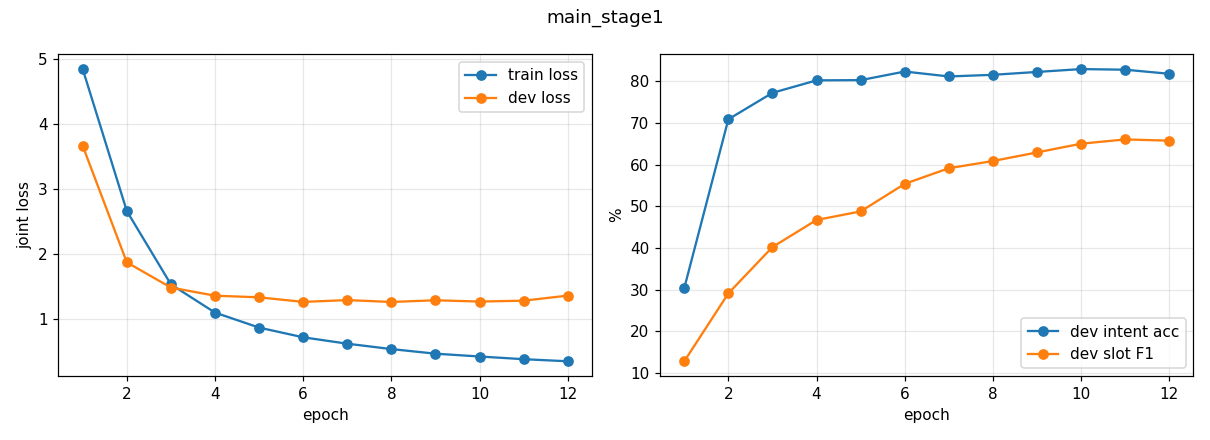

In [17]:
import shutil
from IPython.display import Image, display as show
FORCE_RETRAIN = True      # False: reuse checkpoints already saved by an earlier run of this notebook
if FORCE_RETRAIN:
    for p in list(RESULTS_DIR.glob("main_*")):
        shutil.rmtree(p) if p.is_dir() else p.unlink()
    for p in CKPT_DIR.glob("main_*.pt"):
        p.unlink()
stage1_row = run(ctx, "main_stage1", ModelConfig(), TrainConfig(), rung="NB", note="notebook Stage 1")
ck = torch.load(CKPT_DIR / "main_stage1.pt", map_location="cpu")
display(pd.DataFrame(ck["history"]).round(4))
print("best epoch:", ck["best_epoch"], "| best dev joint:", round(ck["dev"]["joint_score"], 2),
      "| checkpoint:", CKPT_DIR / "main_stage1.pt", "| training time (s):", round(ck["elapsed_s"], 1))
show(Image(filename=str(RESULTS_DIR / "main_stage1" / "curve.png")))

### Stage 1: reload the best checkpoint and evaluate (no further training)

In [18]:
"""Systems built from saved checkpoints without further training.

Every model, whatever its slot head or tag scheme, is converted into per-utterance outputs:
  intent    log-probabilities over the 60 intents (deep and sparse parts kept apart when present)
  tags      per-token log-probabilities over the BIO labels
  presence  optional probabilities that each slot type occurs in the utterance
Those can be averaged across models and decoded in two ways:
  viterbi   best legal tag path under hard BIO rules
  span      span posteriors, thresholded and chosen as a non-overlapping set (the metric counts exact
            spans, and the best threshold for F1 is about half the attainable F1; Lipton et al. 2014),
            optionally blended with a train-only mention table and a soft slot-type presence filter
All tables come from train. All tuning uses dev. Test outputs need allow_test=True (final script only).
"""
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import torch


def load_member(ctx, run_name):
    ck = torch.load(CKPT_DIR / f"{run_name}.pt", map_location="cpu")
    assert ck["vocab"]["word_vocab"] == ctx.assets.word_vocab
    assert ck["vocab"]["slot_labels"] == ctx.assets.slot_labels
    assert ck["vocab"]["intent_labels"] == ctx.assets.intent_labels
    cfg = ModelConfig.from_dict(ck["model_config"])
    model = build_model(cfg, ctx.assets)
    model.load_state_dict(ck["model_state_dict"])
    return model.to(DEVICE).eval(), ck


def crf_log_marginals(em, mask, trans, start, end):
    """Forward-backward. em B,T,K; returns per-token log-marginals B,T,K."""
    B, T, K = em.shape
    alphas = [start.unsqueeze(0) + em[:, 0]]
    for t in range(1, T):
        nxt = torch.logsumexp(alphas[-1].unsqueeze(2) + trans.unsqueeze(0), dim=1) + em[:, t]
        alphas.append(torch.where(mask[:, t].unsqueeze(1), nxt, alphas[-1]))
    betas = [None] * T
    betas[T - 1] = end.unsqueeze(0).expand(B, K)
    for t in range(T - 2, -1, -1):
        step = torch.logsumexp(trans.unsqueeze(0) + (em[:, t + 1] + betas[t + 1]).unsqueeze(1), dim=2)
        betas[t] = torch.where(mask[:, t + 1].unsqueeze(1), step, end.unsqueeze(0).expand(B, K))
    return torch.log_softmax(torch.stack(alphas, 1) + torch.stack(betas, 1), -1)


def _biaffine_tag_probs(head, logits, mask, bio_labels):
    """Approximate token-level BIO probabilities from span probabilities."""
    index = {t: i for i, t in enumerate(bio_labels)}
    probs = torch.softmax(logits, -1).cpu()
    out = []
    for b, n in enumerate(mask.long().sum(1).tolist()):
        p = torch.triu(probs[b, :n, :n, :head.none].permute(2, 0, 1)).permute(1, 2, 0)  # n,n,types
        tags = torch.zeros(n, len(bio_labels))
        for ty, name in enumerate(head.types):
            bi, ii = index.get("B-" + name), index.get("I-" + name)
            for t in range(n):
                if bi is not None:
                    tags[t, bi] += p[t, t:, ty].sum()
                if t > 0:
                    tags[t, ii if ii is not None else bi] += p[:t, t:, ty].sum()
        tags[:, 0] = (1 - tags.sum(1)).clamp_min(1e-4)
        out.append(tags / tags.sum(1, keepdim=True))
    return out


@torch.no_grad()
def collect(ctx, run_name, split, allow_test=False, mc_passes=0, seed=0):
    """Returns {id: outputs} in BIO label space. Plain forward passes are cached on disk."""
    if split == "test" and not allow_test:
        raise RuntimeError("test outputs are only available to the final evaluation")
    cache = RESULTS_DIR / run_name / f"outputs_{split}_v2.pt"    # v2: both intent paths kept per pass
    if mc_passes == 0 and cache.exists():
        return torch.load(cache, map_location="cpu")
    model, ck = load_member(ctx, run_name)
    cfg = model.cfg
    ds = ctx.datasets(cfg, ck["meta"].get("k_extra"), splits=(split,))[split]
    loader = torch.utils.data.DataLoader(ds, batch_size=64, shuffle=False, collate_fn=make_collate(ctx.assets))

    bio = ctx.assets.slot_labels
    bio_index = {t: i for i, t in enumerate(bio)}
    src2bio = []    # collapse map from the head's own tag space into BIO labels
    for t in model.id2tag:
        tb = to_bio(t)
        src2bio.append(bio_index.get(tb, bio_index.get("B-" + tb[2:], 0)))
    src2bio = torch.tensor(src2bio)

    if mc_passes:
        torch.manual_seed(seed)
        model.train()           # dropout on in every sub-module; there is no batch norm in these models
        model.training = False  # the model itself keeps taking its evaluation path
    out = {}
    for raw in loader:
        b = to_device(raw)
        mask = b["attention_mask"]
        passes = max(1, mc_passes)
        intent_acc, tag_acc, pres_acc = 0.0, None, 0.0
        deep, wide = [], []     # both intent paths per pass, so that any intent mix can be applied afterwards
        for _ in range(passes):
            il, sl = model(b)
            intent_acc = intent_acc + torch.softmax(il, -1).cpu()
            if model._wide_logp is not None:
                deep.append(model._deep_logp.cpu())
                wide.append(model._wide_logp.cpu())
            if model._presence is not None:
                pres_acc = pres_acc + torch.sigmoid(model._presence).cpu()
            if cfg.slot_head == "biaffine":
                per = _biaffine_tag_probs(model.biaffine, sl, mask, bio)
                tags = torch.zeros(mask.size(0), mask.size(1), len(bio))
                for i, p in enumerate(per):
                    tags[i, :p.size(0)] = p
            else:
                if cfg.slot_head == "crf":
                    trans, start, end = model.crf.scores()
                    logm = crf_log_marginals(sl, mask, trans, start, end)
                else:
                    logm = torch.log_softmax(sl, -1)
                tags = torch.zeros(*logm.shape[:2], len(bio)).index_add_(2, src2bio, logm.exp().cpu())
            tag_acc = tags if tag_acc is None else tag_acc + tags
        deep = torch.stack(deep, 1) if deep else None     # B, passes, intents
        wide = torch.stack(wide, 1) if wide else None
        intent_lp = torch.log((intent_acc / passes).clamp_min(1e-8)).float()
        tag_lp = torch.log((tag_acc / passes).clamp_min(1e-8)).float()
        for i, n in enumerate(mask.long().sum(1).tolist()):
            out[raw["ids"][i]] = {
                "intent": intent_lp[i],
                "deep": deep[i].float() if deep is not None else None,
                "wide": wide[i].float() if wide is not None else None,
                "tags": tag_lp[i, :n].clone(),
                "presence": (pres_acc[i] / passes).float() if torch.is_tensor(pres_acc) else None,
            }
    del model
    torch.cuda.empty_cache()
    if mc_passes == 0:
        torch.save(out, cache)
    return out


@dataclass
class Decode:
    method: str = "viterbi"     # "viterbi" | "span"
    tau: float = 0.4            # span threshold
    gm: float = 0.0             # weight of the train-only mention table
    eta: float = 0.0            # exponent of the soft slot-type presence filter
    gamma: float = 0.0          # weight of the intent-to-tag PMI prior
    wide_mix: float = -1.0      # deep share of the intent mix; -1 keeps the trained value
    avg: str = "prob"           # how members are averaged: "prob" or "log"
    mask_beta: float = 0.0      # viterbi only: penalty on slot types never seen with the intent
    top_k: int = 1              # viterbi only: number of intents considered jointly
    lam: float = 0.0            # viterbi only: weight of the slot path score against intent


@dataclass
class System:
    name: str
    members: list
    decode: Decode = field(default_factory=Decode)
    flagged: bool = False
    mc: int = 0                 # MC-dropout passes per member; 0 = plain forward pass

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, d):
        return cls(d["name"], list(d["members"]), Decode(**d["decode"]), d.get("flagged", False), d.get("mc", 0))


def _lse(x, axis):
    m = x.max(axis=axis, keepdims=True)
    return np.squeeze(m + np.log(np.exp(x - m).sum(axis=axis, keepdims=True)), axis=axis)


class Decoder:
    """Averaging and decoding over BIO log-probabilities. Tables are built from train only."""

    def __init__(self, assets):
        ts = assets.tagset("bio")
        self.assets = assets
        self.labels = ts.labels
        K = len(ts.labels)
        self.trans = (~torch.as_tensor(ts.allowed)).float() * -1e4
        self.start = (~torch.as_tensor(ts.allowed_start)).float() * -1e4
        self.end = torch.zeros(K)
        self.M, self.S = self.trans.numpy().astype(np.float64), self.start.numpy().astype(np.float64)
        self.types = assets.slot_types
        idx = {t: i for i, t in enumerate(ts.labels)}
        self.B = [idx["B-" + t] if "B-" + t in idx else -1 for t in self.types]
        self.I = [idx.get("I-" + t, -1) for t in self.types]
        self.cont = np.full(K, -1)
        for j, t in enumerate(ts.labels):
            if t != "O":
                self.cont[j] = idx.get("I-" + t[2:], -1)
        self.cont_rows = np.where(self.cont >= 0)[0]
        self.intent_ok = torch.zeros(len(assets.intent_labels), K, dtype=torch.bool)
        self.intent_ok[:, 0] = True
        for i, name in enumerate(assets.intent_labels):
            seen = assets.intent_slot_types.get(name, set())
            for j, t in enumerate(ts.labels):
                if t != "O" and t[2:] in seen:
                    self.intent_ok[i, j] = True
        self.pmi = torch.tensor(assets.intent_tag_pmi(), dtype=torch.float32)
        self._marginals = {}

    def table_entries(self):
        ng_all, ng_type, _ = self.assets.mention_tables()
        return len(ng_all) + len(ng_type)

    # ------------------------------------------------------------ averaging
    def combine(self, outputs, spec):
        ids = list(outputs[0].keys())
        intents, tags, pres = [], [], []
        for i in ids:
            members = [o[i] for o in outputs]
            lps = []
            for m in members:
                if m["deep"] is not None and spec.wide_mix >= 0:
                    # the mix is applied to every pass and renormalised, as the model does when it predicts
                    mixed = spec.wide_mix * m["deep"] + (1 - spec.wide_mix) * m["wide"]
                    lps.append(torch.log(torch.softmax(mixed, -1).mean(0).clamp_min(1e-8)))
                else:
                    lps.append(m["intent"])
            if spec.avg == "log":
                il = torch.stack(lps).mean(0)
                tl = torch.stack([m["tags"] for m in members]).mean(0)
            else:
                il = torch.log(torch.stack([x.exp() for x in lps]).mean(0).clamp_min(1e-8))
                tl = torch.log(torch.stack([m["tags"].exp() for m in members]).mean(0).clamp_min(1e-8))
            intents.append(il)
            tags.append(tl)
            ps = [m["presence"] for m in members if m["presence"] is not None]
            pres.append(torch.stack(ps).mean(0) if ps else None)
        return ids, intents, tags, pres

    # ------------------------------------------------------------ viterbi
    def _decode_batch(self, ems):
        """ems: list of T_i,K tensors. Returns (paths, path scores)."""
        order = sorted(range(len(ems)), key=lambda i: ems[i].size(0))
        paths, scores = [None] * len(ems), [0.0] * len(ems)
        for s in range(0, len(order), 256):
            idx = order[s:s + 256]
            T = max(ems[i].size(0) for i in idx)
            em = torch.zeros(len(idx), T, len(self.labels))
            mask = torch.zeros(len(idx), T, dtype=torch.bool)
            for j, i in enumerate(idx):
                n = ems[i].size(0)
                em[j, :n] = ems[i]
                mask[j, :n] = True
            for j, p in zip(idx, viterbi(em, mask, self.trans, self.start, self.end)):
                paths[j] = p
                scores[j] = float(ems[j][torch.arange(len(p)), torch.tensor(p)].sum())
        return paths, scores

    def _viterbi(self, ids, intents, tags, spec):
        cand_i = [torch.topk(il, spec.top_k).indices.tolist() for il in intents]
        ems, owner = [], []
        for u, (tl, cands) in enumerate(zip(tags, cand_i)):
            for c in cands:
                em = tl
                if spec.gamma:
                    em = em + spec.gamma * self.pmi[c]
                if spec.mask_beta > 0:
                    em = em - spec.mask_beta * (~self.intent_ok[c]).float()
                ems.append(em)
                owner.append((u, c))
        paths, scores = self._decode_batch(ems)
        best = {}
        for (u, c), p, sc in zip(owner, paths, scores):
            total = float(intents[u][c]) + spec.lam * sc / max(len(p), 1)
            if u not in best or total > best[u][0]:
                best[u] = (total, c, p)
        return {ids[u]: (best[u][1], [self.labels[x] for x in best[u][2]]) for u in range(len(ids))}

    # ------------------------------------------------------------ span posteriors
    def span_marginals(self, em):
        """Posterior of every typed span with non-trivial mass. em: T,K log-probabilities."""
        M, K, n = self.M, em.shape[1], em.shape[0]
        a = np.zeros((n, K))
        a[0] = self.S + em[0]
        for t in range(1, n):
            a[t] = _lse(a[t - 1][:, None] + M, 0) + em[t]
        b = np.zeros((n, K))
        for t in range(n - 2, -1, -1):
            b[t] = _lse(M + (em[t + 1] + b[t + 1])[None, :], 1)
        z = _lse(a[-1], 0)
        close = np.zeros((n, K))    # log-mass of ending the span right after this token
        for j in range(n - 1):
            c = M + (em[j + 1] + b[j + 1])[None, :]
            c[self.cont_rows, self.cont[self.cont_rows]] = -np.inf
            close[j] = _lse(c, 1)
        gam = a + b - z
        out = {}
        lim, stop = np.log(0.02), np.log(1e-3)
        for ty, (bi, ii) in enumerate(zip(self.B, self.I)):
            if bi < 0:
                continue
            for i in np.where(gam[:, bi] > lim)[0]:
                cur, tag = a[i, bi], bi
                for j in range(int(i), n):
                    lp = cur + close[j, tag] - z
                    if lp > lim:
                        out[(ty, int(i), j + 1)] = float(np.exp(lp))
                    if ii < 0 or j + 1 >= n:
                        break
                    cur = cur + M[tag, ii] + em[j + 1, ii]
                    tag = ii
                    if cur - z < stop:
                        break
        return out

    def best_set(self, marg, n, tau, low, gm, q, eta, tables):
        """Non-overlapping set of spans maximising the summed (score - tau), by dynamic programming."""
        by_end = {}
        for (ty, s, e), pv in marg.items():
            if gm:
                g = tuple(low[s:e])
                c = tables[0].get(g, 0)
                if c:
                    pv = (1 - gm) * pv + gm * tables[1].get((self.types[ty], g), 0) / c
            if eta and q is not None:
                pv = pv * float(q[ty]) ** eta
            if pv > tau:
                by_end.setdefault(e, []).append((s, ty, pv - tau))
        dp, choice = [0.0] * (n + 1), [None] * (n + 1)
        for e in range(1, n + 1):
            dp[e] = dp[e - 1]
            for s, ty, w in by_end.get(e, ()):
                if dp[s] + w > dp[e]:
                    dp[e], choice[e] = dp[s] + w, (s, ty)
        tags, e = ["O"] * n, n
        while e > 0:
            c = choice[e]
            if c is None:
                e -= 1
            else:
                s, ty = c
                tags[s] = "B-" + self.types[ty]
                for x in range(s + 1, e):
                    tags[x] = "I-" + self.types[ty]
                e = s
        return tags

    def _span(self, ids, intents, tags, pres, spec, lows, key):
        tables = self.assets.mention_tables() if spec.gm else (None, None, None)
        # the PMI prior depends on the predicted intent, so a different intent mix needs new marginals
        mkey = (key, spec.gamma, spec.wide_mix if spec.gamma else None)
        if key is None or mkey not in self._marginals:
            margs = []
            for il, tl in zip(intents, tags):
                em = tl + spec.gamma * self.pmi[int(il.argmax())] if spec.gamma else tl
                margs.append(self.span_marginals(em.numpy().astype(np.float64)))
            if key is not None:
                self._marginals[mkey] = margs
        margs = margs if key is None or mkey not in self._marginals else self._marginals[mkey]
        out = {}
        for u, i in enumerate(ids):
            low = lows[i]
            out[i] = (int(intents[u].argmax()),
                      self.best_set(margs[u], len(low), spec.tau, low, spec.gm, pres[u], spec.eta, tables))
        return out

    def decode(self, outputs, spec, lows=None, key=None):
        """outputs: list of member dicts. Returns id -> (intent id, BIO strings)."""
        ids, intents, tags, pres = self.combine(outputs, spec)
        if spec.method == "span":
            return self._span(ids, intents, tags, pres, spec, lows, key)
        return self._viterbi(ids, intents, tags, spec)


def gold_frame(ctx, split):
    rows = []
    for r in ctx.assets.split(split).itertuples(index=False):
        parsed = parse_annotated_utterance(r.annot_utt)
        rows.append({"id": r.id, "gold_intent_id": ctx.assets.intent2id[r.intent], "gold_tags": parsed["bio"],
                     "low": [t.casefold() for t in parsed["tokens"]]})
    return pd.DataFrame(rows)


def frame_from_decode(decoded, gold):
    rows = []
    for r in gold.itertuples(index=False):
        ci, tg = decoded[r.id]
        rows.append({"id": r.id, "gold_intent_id": r.gold_intent_id, "pred_intent_id": ci,
                     "gold_tags": r.gold_tags, "pred_tags": tg})
    return pd.DataFrame(rows)


def score_system(ctx, system, split, gold, decoder, cache, allow_test=False):
    outs = []
    for m in system.members:
        key = (m, split, system.mc)
        if key not in cache:
            cache[key] = collect(ctx, m, split, allow_test=allow_test, mc_passes=system.mc)
        outs.append(cache[key])
    lows = dict(zip(gold["id"], gold["low"]))
    mkey = (tuple(system.members), split, system.mc, system.decode.avg)
    frame = frame_from_decode(decoder.decode(outs, system.decode, lows, key=mkey), gold)
    return metrics_from_frame(frame), frame


def system_params(lb, members, decode=None, decoder=None):
    """Stored values of a system. Every member is its own checkpoint, so each one counts in full: its trainable
    weights, its frozen Word2Vec table and any anchor copy. Decode-time tables count once."""
    rows = [lb[lb["run"] == m].iloc[0] for m in members]
    total = int(sum(r["params_total"] for r in rows))
    if decode is not None and decoder is not None:
        if decode.gm:
            total += decoder.table_entries()
        if decode.gamma:
            total += int(decoder.pmi.numel())
    return total


def stored_values(members, decode, decoder):
    """The cap's basis: every numeric value a saved system holds at inference. Each member's checkpoint counts in full,
    buffers included (positional tables, CRF masks). TF-IDF idf vectors count once per feature size, the BIO transition
    tables once unless CRF masks already hold them, and the decode tables that the decode uses. Vocabularies and lexicon
    keys are dictionaries, not counted."""
    total, sizes, gaz, bio_needed = 0, set(), False, False
    for m in members:
        ck = torch.load(CKPT_DIR / f"{m}.pt", map_location="cpu")
        cfg = ck["model_config"]
        total += sum(v.numel() for v in ck["model_state_dict"].values())
        # a CRF checkpoint already stores the BIO constraints as masks, so they are counted with it
        bio_needed = bio_needed or not any(k.endswith("trans_mask") for k in ck["model_state_dict"])
        if cfg.get("wide_intent"):
            sizes.add(cfg["wide_intent"])
        gaz = gaz or bool(cfg.get("gaz"))
    for k in sizes:
        word, char = decoder.assets.wide_vectorizers(k)
        total += len(word.idf_) + len(char.idf_)
    if bio_needed:
        total += decoder.trans.numel() + decoder.start.numel() + decoder.end.numel()
    if decode.gm or gaz:
        total += decoder.table_entries()
    if decode.gamma:
        total += int(decoder.pmi.numel())
    return total


def greedy_ensemble(ctx, candidates, lb, gold, decoder, cache, base_decode=None, budget=PARAM_CAP, max_members=8, log=print):
    """Forward selection on dev: add the member that most improves the joint score, within the cap."""
    decode = base_decode or Decode()
    scored = []
    for m in candidates:
        met, _ = score_system(ctx, System(m, [m], decode), "dev", gold, decoder, cache)
        scored.append((met["joint_score"], m))
    scored.sort(reverse=True)
    members = [scored[0][1]]
    best = scored[0][0]
    log(f"ensemble start {members[0]}: dev joint {best:.2f}")
    trail = [{"members": list(members), "joint": best}]
    while len(members) < max_members:
        gain, pick = TIE_MARGIN, None      # a member must add more than a tie on dev
        for m in candidates:
            if m in members or system_params(lb, members + [m]) > budget:
                continue
            met, _ = score_system(ctx, System("t", members + [m], decode), "dev", gold, decoder, cache)
            if met["joint_score"] - best > gain:
                gain, pick = met["joint_score"] - best, m
        if pick is None:
            break
        members.append(pick)
        best += gain
        trail.append({"members": list(members), "joint": best, "params": system_params(lb, members)})
        log(f"ensemble + {pick}: dev joint {best:.2f}, params {system_params(lb, members):,}")
    return members, best, trail


def tune_decode(ctx, members, gold, decoder, cache, mc=0, log=print, tables=True):
    """Stepwise dev tuning of a few scalars. Returns the best Decode and the whole table."""
    rows = []

    def trial(d):
        met, _ = score_system(ctx, System("t", list(members), d, mc=mc), "dev", gold, decoder, cache)
        rows.append({**asdict(d), "intent": met["intent_accuracy"], "slot": met["slot_micro_f1"], "joint": met["joint_score"]})
        return met

    def replace_d(d, **kw):
        return Decode(**{**asdict(d), **kw})

    cur = Decode()
    trial(cur)
    has_wide = any(v["deep"] is not None for v in list(cache[(members[0], "dev", mc)].values())[:1])
    if has_wide:    # keep at least 35% on the deep path, so that one joint model stays the decision maker
        cur = max((replace_d(cur, wide_mix=a) for a in (0.35, 0.5, 0.65, 0.8)),
                  key=lambda d: trial(d)["intent_accuracy"])
    if len(members) > 1:
        log_avg = replace_d(cur, avg="log")
        if trial(log_avg)["joint_score"] > trial(cur)["joint_score"]:
            cur = log_avg
    for g in (0.1, 0.3):
        cand = replace_d(cur, gamma=g)
        if trial(cand)["slot_micro_f1"] > trial(cur)["slot_micro_f1"]:
            cur = cand
    for b in (1.0, 3.0, 10.0):      # hard mask, kept for the record
        trial(replace_d(cur, mask_beta=b))
    for b, l in ((0.0, 1.0), (3.0, 1.0), (3.0, 3.0)):
        trial(replace_d(cur, mask_beta=b, top_k=3, lam=l))
    viterbi_slot = trial(cur)["slot_micro_f1"]

    taus = (0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6)  # 0.5 was the old edge
    span = max((replace_d(cur, method="span", tau=t) for t in taus),
               key=lambda d: trial(d)["slot_micro_f1"])
    best_gm = span
    for gm in ((0.2, 0.4, 0.6) if tables else ()):
        for t in taus:
            cand = replace_d(span, gm=gm, tau=t)
            if trial(cand)["slot_micro_f1"] > trial(best_gm)["slot_micro_f1"]:
                best_gm = cand
    has_pres = any(v["presence"] is not None for v in list(cache[(members[0], "dev", mc)].values())[:1])
    best_all = best_gm
    if has_pres:
        for eta in (0.3, 0.5, 0.8):
            for t in taus:
                cand = replace_d(best_gm, eta=eta, tau=t)
                if trial(cand)["slot_micro_f1"] > trial(best_all)["slot_micro_f1"]:
                    best_all = cand
    if trial(cur)["slot_micro_f1"] > trial(best_all)["slot_micro_f1"]:
        best_all = cur      # plain Viterbi scored higher: keep it, the span decoder is not always the better one
    table = pd.DataFrame(rows).drop_duplicates().sort_values("joint", ascending=False)
    log(table.round(2).head(10).to_string(index=False))
    log(f"slot F1, viterbi {viterbi_slot:.2f}, best decode {trial(best_all)['slot_micro_f1']:.2f}")
    return best_all, table


TIE_MARGIN = 0.8    # dev joint points: the one-seed tie margin of the protocol


def tuned_decode(ctx, members, gold, decoder, cache, mc=0):
    """tune_decode, except that a mention table stays in the decode only if it beats the best table-free decode by TIE_MARGIN."""
    dec, table = tune_decode(ctx, members, gold, decoder, cache, mc=mc)
    if not dec.gm:
        return dec, table
    free, free_table = tune_decode(ctx, members, gold, decoder, cache, mc=mc, tables=False)

    def joint(d):
        return score_system(ctx, System("t", list(members), d, mc=mc), "dev", gold, decoder, cache)[0]["joint_score"]

    if joint(dec) - joint(free) < TIE_MARGIN:
        return free, free_table
    return dec, table

In [19]:
def own_decoding(run_name, split):
    model, ck = load_member(ctx, run_name)
    data = ctx.datasets(model.cfg, ck["meta"].get("k_extra"), splits=(split,))[split]
    loader = torch.utils.data.DataLoader(data, batch_size=64, shuffle=False, collate_fn=make_collate(assets))
    r = predict(model, loader, assets)
    del model
    return r, ck

retrained = {}
r, ck = own_decoding("main_stage1", "dev")
table, _ = oov_table(r["pred_frame"], ctx.oov["dev"])
retrained["Stage1"] = {"intent_accuracy": r["intent_accuracy"], "slot_micro_f1": r["slot_micro_f1"]}
print(f"Stage 1 dev (retrained here): intent accuracy {r['intent_accuracy']:.2f} | slot micro-F1 {r['slot_micro_f1']:.2f}")
display(table.round(2))

Stage 1 dev (retrained here): intent accuracy 82.83 | slot micro-F1 66.09


,group,n,intent_accuracy,slot_micro_f1,exact_match
0,No-Train-OOV,1669,86.10,71.51,62.07
1,NonSlot-Train-OOV,149,55.70,59.88,44.30
2,Slot-Train-OOV,215,76.28,34.51,10.70
3,Overall,2033,82.83,66.09,55.34


# Stage 2: diagnosis and improvement

**Diagnosed Stage-1 weaknesses (dev).** Slot F1 collapses on utterances whose slot contains a word never seen in
training (Slot-Train-OOV), and the gap survives matching on length and slot count. Intent accuracy drops sharply
when an unseen word occurs outside the slots (NonSlot-Train-OOV). The Stage-1 curve was still improving at its last
epochs under a constant learning rate.

**Method ladder.** Every rung screens variants on one seed, combines helpful ones greedily, and confirms the top
candidates on three seeds, always on dev. Rungs: A training recipe; B open-vocabulary word representations; C slot
and intent heads and task interaction; D encoder family and size; R regularisers; H random search; E decoding
options and ensembles. All runs are listed below, including the unsuccessful ones.

In [20]:
lb_path = RESULTS_DIR / "leaderboard.csv"
if lb_path.exists():
    lb = pd.read_csv(lb_path)
    lb = lb[lb["rung"] != "NB"]
    cols = ["run", "rung", "note", "flagged", "params_total", "best_epoch", "dev_intent", "dev_slot_f1", "dev_joint",
            "f1_no_oov", "f1_slot_oov", "gain_slot_oov", "targeted_adv"]
    pd.set_option("display.max_rows", 300)
    pd.set_option("display.max_colwidth", 90)
    display(lb[[c for c in cols if c in lb.columns]].sort_values(["rung", "dev_joint"]))

,run,rung,note,flagged,params_total,best_epoch,dev_intent,dev_slot_f1,dev_joint,f1_no_oov,f1_slot_oov,gain_slot_oov,targeted_adv
1,A1_fresh_recipe,A,"recipe: 40 epochs, cosine, warm-up, label smoothing .1, word dropout .1",False,4344472,30,84.60,72.59,78.60,77.53,44.77,10.26,4.24
2,A1_ft_recipe,A,"recipe: 40 epochs, cosine, warm-up, label smoothing .1, word dropout .1",False,4344472,24,84.90,72.38,78.64,77.94,39.77,5.26,-1.17
0,A1_fresh_lr5e-4,A,"recipe: 40 epochs, cosine, warm-up, label smoothing .1, word dropout .1",False,4344472,40,84.75,73.44,79.10,79.00,43.67,9.16,1.67
7,A2_emb0,A2,A1_fresh_lr5e-4 + emb0,False,4344472,32,86.13,68.19,77.16,73.65,37.71,3.20,1.06
3,A2_bs32,A2,A1_fresh_lr5e-4 + bs32,False,4344472,35,84.31,70.55,77.43,76.24,39.50,4.99,0.26
5,A2_drop.25,A2,A1_fresh_lr5e-4 + drop.25,False,4344472,36,84.16,71.81,77.99,77.72,38.24,3.73,-2.48
16,A2_slotdrop.2,A2,A1_fresh_lr5e-4 + slotdrop.2,False,4344472,32,84.70,72.05,78.38,76.43,51.54,17.03,12.11
6,A2_emb.1,A2,A1_fresh_lr5e-4 + emb.1,False,4344472,36,85.44,71.44,78.44,77.03,40.00,5.49,-0.03
18,A2_wdrop.2,A2,A1_fresh_lr5e-4 + wdrop.2,False,4344472,40,85.15,71.85,78.50,77.20,43.21,8.70,3.01
10,A2_ls0,A2,A1_fresh_lr5e-4 + ls0,False,4344472,34,84.31,73.19,78.75,79.02,41.45,6.94,-0.57


## Stage 2: train every member of the selected systems

D2f_flagged__s7 | D2f_flagged seed 7
Word2Vec (cached): raw 302,866 -> casefold 261,587 x 300


[main_D2f_flagged__s7] epoch 00 | dev 8.1355 | intent 1.23 | slot 0.04 | joint 0.63


[main_D2f_flagged__s7] epoch 01 | train 9.1050 | dev 2.0623 | intent 80.23 | slot 11.49 | joint 45.86 | 8s


[main_D2f_flagged__s7] epoch 02 | train 5.6719 | dev 1.5537 | intent 81.70 | slot 37.44 | joint 59.57 | 16s


[main_D2f_flagged__s7] epoch 03 | train 4.1738 | dev 1.0975 | intent 84.51 | slot 58.51 | joint 71.51 | 24s


[main_D2f_flagged__s7] epoch 04 | train 3.2884 | dev 0.9153 | intent 86.62 | slot 65.11 | joint 75.87 | 33s


... (38 outputs left out)

[main_D2f_flagged__s7] best epoch 34 | dev intent 87.95 | slot 81.92 | joint 84.94 | params 19,140,936 (trainable 5,721,636) | 302s | peak RAM 3696 MB | ckpt C:\Users\user\massive_joint_nlu\checkpoints\main_D2f_flagged__s7.pt


            group    n  intent_accuracy  slot_micro_f1  exact_match
     No-Train-OOV 1669            90.35          84.67        75.01
NonSlot-Train-OOV  149            63.76          73.37        47.65
   Slot-Train-OOV  215            86.05          69.67        52.56
          Overall 2033            87.95          81.92        70.63
[main_D2f_flagged__s7] matched control: {'matched_no_oov_f1': 85.55, 'slot_oov_f1': 69.67, 'gap': 15.89, 'avg_tokens': 7.67, 'avg_slots': 1.49, 'matched_avg_tokens': 7.67, 'matched_avg_slots': 1.49}


parameters: total 19,140,936 | trainable 5,721,636 | best epoch 34 of 40 | best dev joint 84.94 | checkpoint C:\Users\user\massive_joint_nlu\checkpoints\main_D2f_flagged__s7.pt | training time 302 s
dev now: intent 87.95 slot 81.92 | ladder run: intent 88.59 slot 81.73


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_joint,elapsed_s
29,29,1.6795,0.7899,87.8013,81.7064,84.7538,224.4660
30,30,1.6728,0.7962,87.7029,81.8068,84.7548,233.2519
31,31,1.6654,0.7971,87.6537,81.3347,84.4942,240.7383
32,32,1.6526,0.7987,87.6537,81.7613,84.7075,247.6219
33,33,1.6459,0.8003,87.9488,81.7177,84.8333,254.4090
34,34,1.6438,0.8017,87.9488,81.9235,84.9362,261.2232
35,35,1.6393,0.7989,87.8997,81.6020,84.7508,268.2688
36,36,1.6397,0.8022,87.8997,81.6880,84.7938,275.0100
37,37,1.6372,0.8021,87.8997,81.6788,84.7892,281.7804
38,38,1.6335,0.8022,88.1456,81.6880,84.9168,288.4916


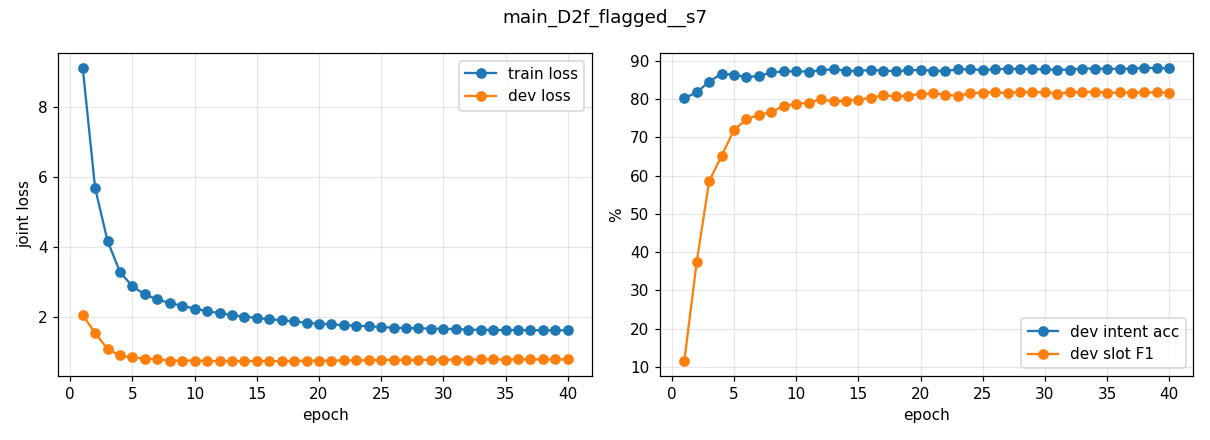

R1_sam.2__s7 | R1_sam.2 seed 7


[main_R1_sam.2__s7] epoch 00 | dev 8.0862 | intent 0.74 | slot 2.83 | joint 1.78


[main_R1_sam.2__s7] epoch 01 | train 9.1981 | dev 2.0778 | intent 80.67 | slot 12.85 | joint 46.76 | 12s


[main_R1_sam.2__s7] epoch 02 | train 5.7513 | dev 1.5900 | intent 82.19 | slot 39.94 | joint 61.07 | 24s


[main_R1_sam.2__s7] epoch 03 | train 4.3066 | dev 1.1242 | intent 84.26 | slot 60.60 | joint 72.43 | 36s


[main_R1_sam.2__s7] epoch 04 | train 3.3652 | dev 0.9289 | intent 85.93 | slot 68.25 | joint 77.09 | 48s


... (27 outputs left out)

[main_R1_sam.2__s7] best epoch 22 | dev intent 88.15 | slot 81.37 | joint 84.76 | params 5,631,336 (trainable 5,631,336) | 393s | peak RAM 3696 MB | ckpt C:\Users\user\massive_joint_nlu\checkpoints\main_R1_sam.2__s7.pt


            group    n  intent_accuracy  slot_micro_f1  exact_match
     No-Train-OOV 1669            90.65          84.63        75.13
NonSlot-Train-OOV  149            63.09          70.18        45.64
   Slot-Train-OOV  215            86.05          66.55        48.37
          Overall 2033            88.15          81.37        70.14
[main_R1_sam.2__s7] matched control: {'matched_no_oov_f1': 85.63, 'slot_oov_f1': 66.55, 'gap': 19.07, 'avg_tokens': 7.67, 'avg_slots': 1.49, 'matched_avg_tokens': 7.67, 'matched_avg_slots': 1.49}


parameters: total 5,631,336 | trainable 5,631,336 | best epoch 22 of 30 | best dev joint 84.76 | checkpoint C:\Users\user\massive_joint_nlu\checkpoints\main_R1_sam.2__s7.pt | training time 393 s
dev now: intent 88.15 slot 81.37 | ladder run: intent 88.0 slot 82.0


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_joint,elapsed_s
19,19,1.8940,0.7590,87.5061,80.6378,84.0720,247.9498
20,20,1.8651,0.7685,87.5553,80.4243,83.9898,259.7951
21,21,1.8345,0.7759,87.8997,80.3941,84.1469,271.8772
22,22,1.8190,0.7732,88.1456,81.3696,84.7576,284.1645
23,23,1.8077,0.7767,87.3094,80.9319,84.1206,296.7033
24,24,1.7856,0.7783,87.8013,80.9947,84.3980,311.3267
25,25,1.7668,0.7819,87.8505,80.7829,84.3167,327.1706
26,26,1.7542,0.7877,88.1456,80.6680,84.4068,340.3011
27,27,1.7445,0.7861,87.9980,80.9284,84.4632,353.8724
28,28,1.7308,0.7853,87.9980,80.9344,84.4662,366.2507


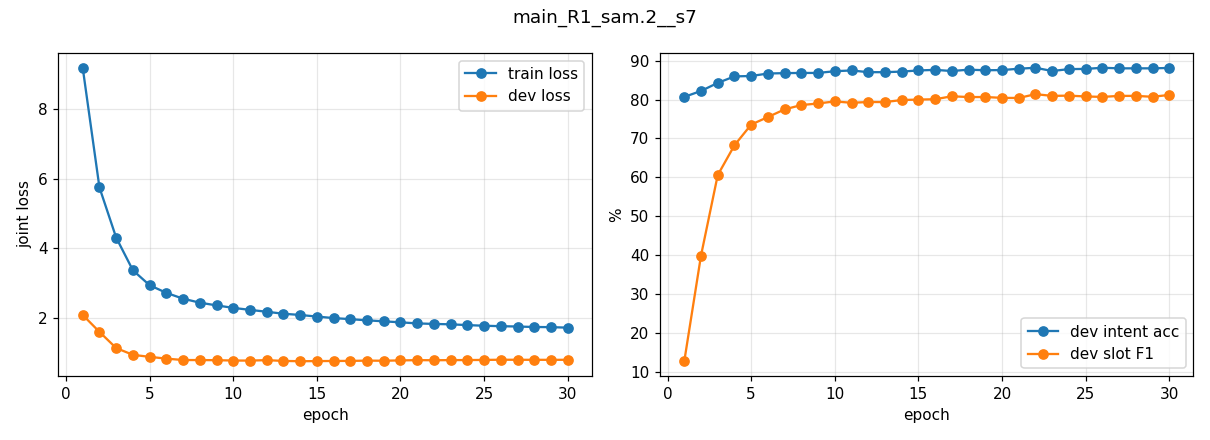

In [21]:
MEMBER_SPECS = {'D2f_flagged__s7': {'family': 'D2f_flagged',
                     'frozen_dim': 300,
                     'init': 'fresh',
                     'k_extra': 40000,
                     'ladder_dev_intent': 88.59,
                     'ladder_dev_slot_f1': 81.73,
                     'model_config': {'adapters': ['char'],
                                      'anchor': False,
                                      'aux_lm': False,
                                      'coint': False,
                                      'd_ff': 768,
                                      'd_model': 256,
                                      'decode': 'viterbi',
                                      'dropout': 0.15,
                                      'dual_emb': False,
                                      'encoder': 'bilstm',
                                      'factorized': False,
                                      'frozen_dim': 300,
                                      'frozen_map': True,
                                      'gaz': False,
                                      'hier_intent': False,
                                      'intent_to_slot': False,
                                      'interaction': False,
                                      'label_attn': False,
                                      'lstm_hidden': 256,
                                      'lstm_layers': 2,
                                      'n_frozen': 44731,
                                      'n_heads': 4,
                                      'n_layers': 4,
                                      'pooling': 'mean',
                                      'pre_lstm': False,
                                      'presence': False,
                                      'refine': False,
                                      'rel_bias': False,
                                      'slot_head': 'crf',
                                      'slot_to_intent': False,
                                      'supcon_dim': 0,
                                      'tag_scheme': 'bio',
                                      'task_top': False,
                                      'wide_intent': 10000,
                                      'wide_mix': 0.5,
                                      'wide_slot_bits': 0,
                                      'wide_slot_mix': 0.5},
                     'note': 'D2f_flagged seed 7',
                     'run': 'D2f_flagged__s7',
                     'rung': 'D2',
                     'train_config': {'adv_eps': 0.0,
                                      'anchor_lambda': 0.0,
                                      'batch_size': 64,
                                      'boundary_eps': 0.0,
                                      'clip': 1.0,
                                      'cons_alpha': 0.0,
                                      'ema_decay': 0.0,
                                      'emb_lr_mult': 1.0,
                                      'epochs': 40,
                                      'label_smoothing': 0.1,
                                      'lambda_aux': 0.0,
                                      'lambda_intent': 1.0,
                                      'lambda_presence': 0.2,
                                      'lambda_slot': 2.0,
                                      'lambda_token_intent': 0.0,
                                      'lr': 0.001,
                                      'lwtr': 0.0,
                                      'mention_dropout': 0.0,
                                      'mention_replace': 0.0,
                                      'mixup_alpha': 0.0,
                                      'o_weight': 1.0,
                                      'patience': 8,
                                      'rare_alpha': 1.0,
                                      'rdrop_alpha': 0.0,
                                      'sam_rho': 0.0,
                                      'schedule': 'cosine',
                                      'seed': 7,
                                      'sis': 0.0,
                                      'slot_dropout': 0.0,
                                      'supcon_lambda': 0.0,
                                      'swap_frac': 0.7,
                                      'swap_prob': 0.1,
                                      'warmup_epochs': 1.0,
                                      'weight_decay': 0.0001,
                                      'wide_dropout': 0.3,
                                      'wide_lr': 0.05,
                                      'wide_wd': 0.01,
                                      'word_dropout': 0.1}},
 'R1_sam.2__s7': {'family': 'R1_sam.2',
                  'frozen_dim': 300,
                  'init': 'fresh',
                  'k_extra': None,
                  'ladder_dev_intent': 88.0,
                  'ladder_dev_slot_f1': 82.0,
                  'model_config': {'adapters': ['char'],
                                   'anchor': False,
                                   'aux_lm': False,
                                   'coint': False,
                                   'd_ff': 768,
                                   'd_model': 256,
                                   'decode': 'viterbi',
                                   'dropout': 0.15,
                                   'dual_emb': False,
                                   'encoder': 'bilstm',
                                   'factorized': False,
                                   'frozen_dim': 300,
                                   'frozen_map': True,
                                   'gaz': False,
                                   'hier_intent': False,
                                   'intent_to_slot': False,
                                   'interaction': False,
                                   'label_attn': False,
                                   'lstm_hidden': 256,
                                   'lstm_layers': 2,
                                   'n_frozen': 0,
                                   'n_heads': 4,
                                   'n_layers': 4,
                                   'pooling': 'mean',
                                   'pre_lstm': False,
                                   'presence': False,
                                   'refine': False,
                                   'rel_bias': False,
                                   'slot_head': 'crf',
                                   'slot_to_intent': False,
                                   'supcon_dim': 0,
                                   'tag_scheme': 'bio',
                                   'task_top': False,
                                   'wide_intent': 10000,
                                   'wide_mix': 0.5,
                                   'wide_slot_bits': 0,
                                   'wide_slot_mix': 0.5},
                  'note': 'R1_sam.2 seed 7',
                  'run': 'R1_sam.2__s7',
                  'rung': 'R1',
                  'train_config': {'adv_eps': 0.0,
                                   'anchor_lambda': 0.0,
                                   'batch_size': 64,
                                   'boundary_eps': 0.0,
                                   'clip': 1.0,
                                   'cons_alpha': 0.0,
                                   'ema_decay': 0.0,
                                   'emb_lr_mult': 1.0,
                                   'epochs': 40,
                                   'label_smoothing': 0.1,
                                   'lambda_aux': 0.0,
                                   'lambda_intent': 1.0,
                                   'lambda_presence': 0.2,
                                   'lambda_slot': 2.0,
                                   'lambda_token_intent': 0.0,
                                   'lr': 0.001,
                                   'lwtr': 0.0,
                                   'mention_dropout': 0.0,
                                   'mention_replace': 0.0,
                                   'mixup_alpha': 0.0,
                                   'o_weight': 1.0,
                                   'patience': 8,
                                   'rare_alpha': 1.0,
                                   'rdrop_alpha': 0.0,
                                   'sam_rho': 0.2,
                                   'schedule': 'cosine',
                                   'seed': 7,
                                   'sis': 0.0,
                                   'slot_dropout': 0.0,
                                   'supcon_lambda': 0.0,
                                   'swap_frac': 0.0,
                                   'swap_prob': 0.0,
                                   'warmup_epochs': 1.0,
                                   'weight_decay': 0.0001,
                                   'wide_dropout': 0.3,
                                   'wide_lr': 0.05,
                                   'wide_wd': 0.01,
                                   'word_dropout': 0.1}}}
SYSTEM_SPECS = {'flagged_single': {'decode': {'avg': 'prob',
                               'eta': 0.0,
                               'gamma': 0.0,
                               'gm': 0.0,
                               'lam': 0.0,
                               'mask_beta': 0.0,
                               'method': 'span',
                               'tau': 0.55,
                               'top_k': 1,
                               'wide_mix': 0.5},
                    'flagged': True,
                    'mc': 0,
                    'members': ['D2f_flagged__s7'],
                    'name': 'flagged_single'},
 'strict_single': {'decode': {'avg': 'prob',
                              'eta': 0.0,
                              'gamma': 0.1,
                              'gm': 0.0,
                              'lam': 0.0,
                              'mask_beta': 0.0,
                              'method': 'span',
                              'tau': 0.5,
                              'top_k': 1,
                              'wide_mix': 0.65},
                   'flagged': False,
                   'mc': 0,
                   'members': ['R1_sam.2__s7'],
                   'name': 'strict_single'}}

for name, spec in MEMBER_SPECS.items():
    print("=" * 90)
    print(name, "|", spec["note"])
    mcfg = ModelConfig.from_dict(spec["model_config"])
    tcfg = TrainConfig.from_dict(spec["train_config"])
    row = run(ctx, "main_" + name, mcfg, tcfg, init=None if spec["init"] == "fresh" else spec["init"],
              k_extra=spec["k_extra"], frozen_dim=spec["frozen_dim"], rung="NB", note="notebook retrain of " + name)
    assert row["params_total"] <= PARAM_CAP
    ck = torch.load(CKPT_DIR / f"main_{name}.pt", map_location="cpu")
    print(f"parameters: total {ck['params_total']:,} | trainable {ck['params_trainable']:,} | best epoch {ck['best_epoch']} of "
          f"{ck['epochs_run']} | best dev joint {ck['dev']['joint_score']:.2f} | checkpoint {CKPT_DIR / f'main_{name}.pt'} | "
          f"training time {ck['elapsed_s']:.0f} s")
    print(f"dev now: intent {row['dev_intent']} slot {row['dev_slot_f1']} | ladder run: intent {spec['ladder_dev_intent']} slot {spec['ladder_dev_slot_f1']}")
    display(pd.DataFrame(ck["history"]).round(4).tail(12))
    show(Image(filename=str(RESULTS_DIR / ("main_" + name) / "curve.png")))

## Final evaluation: one-time test results and reproduction check

Test is evaluated **once**, by `run_final_test.py`, on the saved checkpoints of the selected runs, after every
selection was made on dev. This notebook never evaluates test. It reads those results and checks that the systems match
the ones tested. It also retrains the same systems and compares their dev numbers with the logged ones, asserting a
largest gap of at most one point. GPU kernels are not bit-deterministic, so a retrain can differ slightly and can stop
at a different epoch. The reported test numbers belong to the saved checkpoints, not to these retrained models.

In [22]:
import json
lb_now = rebuild_leaderboard()
decoder = Decoder(assets)
golds = {"dev": gold_frame(ctx, "dev")}
cache = {}
FINAL = RESULTS_DIR / "final"
assert (FINAL / "final_comparison.csv").exists(), "run run_final_test.py first: it holds the one-time test evaluation"
lock = json.loads((FINAL / "TEST_EVALUATED.json").read_text())
print("test was evaluated once, by run_final_test.py, at", lock["time"])
# The systems that were tested must be the systems this notebook retrains, with the same members and decode.
assert set(lock["systems"]) == set(SYSTEM_SPECS), "the notebook and the one-time test disagree on the systems"
for label, s in SYSTEM_SPECS.items():
    locked = lock["systems"][label]
    assert locked["members"] == s["members"] and locked["decode"] == s["decode"] and locked["flagged"] == s["flagged"], label
logged = pd.read_csv(FINAL / "final_comparison.csv")
logged = logged[logged["split"] == "dev"].set_index("system")
for label, s in SYSTEM_SPECS.items():
    system = System(label, ["main_" + m for m in s["members"]], Decode(**s["decode"]), s["flagged"], s.get("mc", 0))
    m, frame = score_system(ctx, system, "dev", golds["dev"], decoder, cache)
    table, _ = oov_table(frame, ctx.oov["dev"])
    retrained[label] = {"intent_accuracy": m["intent_accuracy"], "slot_micro_f1": m["slot_micro_f1"]}
    print(label, "dev (retrained here)")
    display(table.round(2))
check = pd.DataFrame([{"system": k, "intent retrained": round(v["intent_accuracy"], 2), "intent logged": logged.loc[k, "intent_accuracy"],
                       "slot F1 retrained": round(v["slot_micro_f1"], 2), "slot F1 logged": logged.loc[k, "slot_micro_f1"]}
                      for k, v in retrained.items()])
check["intent diff"] = (check["intent retrained"] - check["intent logged"]).round(2)
check["slot F1 diff"] = (check["slot F1 retrained"] - check["slot F1 logged"]).round(2)
display(check)
REPRO_TOL = 1.0    # points; retrained numbers may differ slightly because GPU kernels are not bit-deterministic
worst = check[["intent diff", "slot F1 diff"]].abs().max().max()
print(f"largest gap between retrained and logged dev numbers: {worst:.2f} points (tolerance {REPRO_TOL})")
assert worst <= REPRO_TOL, "retrained models do not reproduce the logged dev numbers"
display(pd.read_csv(FINAL / "final_comparison.csv").drop(columns=["members"]))
# The error analysis describes the strict-track system that is best on dev, not the first key alphabetically.
strict_names = [k for k in SYSTEM_SPECS if not SYSTEM_SPECS[k]["flagged"] and not SYSTEM_SPECS[k].get("mc", 0)]
PRIMARY = max(strict_names, key=lambda k: (logged.loc[k, "intent_accuracy"] + logged.loc[k, "slot_micro_f1"]) / 2)
print("primary system (strict track, best on dev):", PRIMARY)

test was evaluated once, by run_final_test.py, at 2026-11-02 10:09:27


flagged_single dev (retrained here)


,group,n,intent_accuracy,slot_micro_f1,exact_match
0,No-Train-OOV,1669,90.35,85.26,75.07
1,NonSlot-Train-OOV,149,63.76,76.13,49.66
2,Slot-Train-OOV,215,86.05,69.01,48.84
3,Overall,2033,87.95,82.51,70.44


strict_single dev (retrained here)


,group,n,intent_accuracy,slot_micro_f1,exact_match
0,No-Train-OOV,1669,90.83,85.17,75.31
1,NonSlot-Train-OOV,149,65.77,74.21,48.99
2,Slot-Train-OOV,215,86.05,68.21,46.51
3,Overall,2033,88.49,82.27,70.34


,system,intent retrained,intent logged,slot F1 retrained,slot F1 logged,intent diff,slot F1 diff
0,Stage1,82.83,82.83,66.09,66.09,0.00,0.00
1,flagged_single,87.95,88.59,82.51,81.99,-0.64,0.52
2,strict_single,88.49,88.15,82.27,82.83,0.34,-0.56


largest gap between retrained and logged dev numbers: 0.64 points (tolerance 1.0)


,system,split,total_params,stored_values,trainable_params,intent_accuracy,slot_micro_f1,exact_match,best_epoch_of_epochs_run,slot_f1_no_oov,slot_f1_slot_oov
0,Stage1,dev,4344472,4372736,4344472,82.83,66.09,55.34,11/12,71.51,34.51
1,strict_single,dev,5637816,5669696,5631336,88.15,82.83,70.93,22/30,85.24,70.57
2,flagged_single,dev,19140936,19172816,5721636,88.59,81.99,70.14,23/31,84.81,69.40
3,Stage1,test,4344472,4372736,4344472,81.57,63.23,54.14,11/12,70.08,29.90
4,strict_single,test,5637816,5669696,5631336,86.42,79.01,67.48,22/30,82.87,62.99
5,flagged_single,test,19140936,19172816,5721636,86.58,79.38,67.22,23/31,83.10,64.59


primary system (strict track, best on dev): strict_single


### Paired bootstrap, difficulty-matched OOV gap and subgroup tables (test, one-time evaluation)

In [23]:
boot = pd.read_csv(FINAL / "bootstrap_vs_stage1.csv")
display(boot[boot["split"] == "test"])
display(pd.read_csv(FINAL / "matched_control_test.csv"))
oov = pd.read_csv(FINAL / "final_oov_tables.csv")
display(oov[oov["split"] == "test"])

,system,split,group,n,slot_f1_gain,slot_f1_ci_low,slot_f1_ci_high,intent_gain,intent_ci_low,intent_ci_high
4,strict_single,test,Overall,2974,15.78,14.04,17.49,4.84,3.63,5.95
5,strict_single,test,No-Train-OOV,2411,12.79,11.11,14.51,4.40,3.19,5.64
6,strict_single,test,NonSlot-Train-OOV,222,13.96,7.06,21.06,5.41,-0.45,10.81
7,strict_single,test,Slot-Train-OOV,341,33.10,28.09,37.60,7.62,3.52,12.32
12,flagged_single,test,Overall,2974,16.15,14.48,17.77,5.01,3.87,6.15
13,flagged_single,test,No-Train-OOV,2411,13.03,11.38,14.72,4.65,3.57,5.81
14,flagged_single,test,NonSlot-Train-OOV,222,13.41,5.39,21.94,3.60,-2.25,9.46
15,flagged_single,test,Slot-Train-OOV,341,34.70,29.68,39.58,8.50,4.40,12.62


,system,split,matched_no_oov_f1,slot_oov_f1,gap,avg_tokens,avg_slots,matched_avg_tokens,matched_avg_slots
0,Stage1,test,70.04,29.90,40.15,7.77,1.51,7.77,1.5
1,strict_single,test,84.09,62.99,21.10,7.77,1.51,7.77,1.5
2,flagged_single,test,84.29,64.59,19.69,7.77,1.51,7.77,1.5


,system,split,group,n,intent_accuracy,slot_micro_f1,exact_match
12,Stage1,test,No-Train-OOV,2411,84.74,70.08,61.72
13,Stage1,test,NonSlot-Train-OOV,222,62.16,55.34,45.05
14,Stage1,test,Slot-Train-OOV,341,71.85,29.90,6.45
15,Stage1,test,Overall,2974,81.57,63.23,54.14
16,strict_single,test,No-Train-OOV,2411,89.13,82.87,73.25
17,strict_single,test,NonSlot-Train-OOV,222,67.57,69.30,51.35
18,strict_single,test,Slot-Train-OOV,341,79.47,62.99,37.24
19,strict_single,test,Overall,2974,86.42,79.01,67.48
20,flagged_single,test,No-Train-OOV,2411,89.38,83.10,72.83
21,flagged_single,test,NonSlot-Train-OOV,222,65.77,68.75,48.20


### Error cases of the improved model (test)

In [24]:
errs = pd.read_csv(FINAL / f"error_cases_{PRIMARY}.csv")
print(len(errs), "test utterances with an intent or slot error for", PRIMARY)
pd.set_option("display.max_colwidth", 120)
display(errs.groupby("error").head(3))

967 test utterances with an intent or slot error for strict_single


,id,group,utt,gold_intent,pred_intent,gold_slots,pred_slots,error
0,8,No-Train-OOV,pink is all we need,iot_hue_lightchange,play_music,"[('color_type', 'pink')]","[('artist_name', 'pink')]",intent+slot
1,14,NonSlot-Train-OOV,and the darkness has fallen,iot_hue_lighton,weather_query,[],[],intent
2,27,No-Train-OOV,it's dirty here make some noise,iot_cleaning,play_music,[],[],intent
3,31,No-Train-OOV,hoover the hallway,iot_cleaning,email_querycontact,"[('house_place', 'hallway')]",[],intent+slot
4,71,Slot-Train-OOV,i like senatra songs,music_likeness,music_likeness,"[('artist_name', 'senatra')]","[('music_genre', 'senatra')]",slot
5,100,No-Train-OOV,what's the week's forecast,weather_query,weather_query,"[('time', ""week's"")]","[('date', ""week's"")]",slot
6,122,NonSlot-Train-OOV,send a giggle my way,general_joke,email_sendemail,[],[],intent
7,170,No-Train-OOV,do they deliver home,takeaway_query,takeaway_query,"[('order_type', 'deliver')]",[],slot
13,281,No-Train-OOV,what is the exchange rate of us dollar to pound sterling,news_query,qa_currency,"[('news_topic', 'exchange rate of us dollar to pound sterling')]","[('currency_name', 'us dollar'), ('currency_name', 'pound sterling')]",intent+slot


## Notes for the report
* Dev numbers are recomputed here from retrained checkpoints and checked against the ladder log.
* Test numbers are the one-time results of `run_final_test.py` on the saved ladder checkpoints.
* Error analysis, limitations and future work belong in `report.pdf`.